# Retail Demand Forecasting — Exploratory Data Analysis

**Scope:** EDA, the preprocessing policy, cutoff-safe feature extraction, complete 30-day targets, and chronological split preparation. Sections 13–14 summarize features and run baseline/CatBoost comparisons and feature-family ablations. Sections 1–10 retain their original EDA outputs; implementation begins in Section 12.

**Source:** *Pricing Data Scientist Assessment Task* (product × day observations, future 30-day unit-sales total). All findings are empirical only after this notebook runs on `candidate_dataset.parquet`.

**Questions:** integrity and continuity; missing record vs. zero sales vs. zero stock; demand intermittency and spikes; stock availability/censoring; price and discount dynamics; taxonomy and competition; time trends and calendar effects; appropriate history windows.

**Usage:** This copy lives in `src/okala`. Data and generated artifacts use the project `data/` directory. The default dataset is `../../data/candidate_dataset.parquet`; override it with `DATA_PATH` if needed. Install the dependencies declared in `../../pyproject.toml`, including `jdatetime`. Local package imports resolve through the project `src/` directory. Launch the kernel from this notebook directory, the project root, or its enclosing repository root. Existing outputs are preserved from the original notebook; this copy has not been executed.

Section 15 adds development-only XGBoost comparisons, rotating training origins, sparse-product routing and calibrated blends. The earlier final-test report is preserved.

Section 16 adds retrospective statistical diagnostics and native model explanations without retraining or changing model selection.


In [1]:
from pathlib import Path
import os
import sys

# Locate the project from the notebook directory or a repository-root kernel.
PROJECT_ROOT = next(
    (
        candidate
        for parent in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
        for candidate in (parent, parent / "okala")
        if (candidate / "pyproject.toml").is_file()
        and (candidate / "src/okala/features.py").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate the okala project. Start the notebook kernel from "
        "src/okala, the project root, or its enclosing repository root."
    )
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import jdatetime
from tqdm.auto import tqdm
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

In [2]:
DATA_PATH = Path(os.getenv("DATA_PATH", PROJECT_ROOT / "data/candidate_dataset.parquet")).expanduser().resolve()
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset missing: {DATA_PATH.resolve()}. Place candidate_dataset.parquet in the project data directory or set DATA_PATH.")

df = pd.read_parquet(DATA_PATH)
df["date_jalali"] = df["date"].astype(str)

def to_gregorian(s):
    return jdatetime.date(
        int(s[:4]), int(s[4:6]), int(s[6:8])
    ).togregorian()

date_map = {s: to_gregorian(s) for s in df["date_jalali"].unique()}
df["date"] = pd.to_datetime(df["date_jalali"].map(date_map), errors="raise")


print(f"Dataset: {DATA_PATH} | rows={len(df):,} | columns={df.shape[1]}")
display(df)

Dataset: /home/ali/Desktop/personal/projects/resume/okala/data/candidate_dataset.parquet | rows=902,438 | columns=14


,date,product_id,brand_id,Level1,Level2,Level3,Level4,Level5,sale_qty,stock_qty,num_stores_with_stock,discount_pct,price,date_jalali
0,2024-09-21,P_0001,B_043,L1_003,L2_012,L3_024,L4_036,L5_138,3784.5,110840.02,277,19.2,434667.0,14030631
1,2024-09-22,P_0001,B_043,L1_003,L2_012,L3_024,L4_036,L5_138,2840.05,109396.02,277,19.2,433960.0,14030701
2,2024-09-23,P_0001,B_043,L1_003,L2_012,L3_024,L4_036,L5_138,2448.67,109004.64,277,22.3,434770.0,14030702
3,2024-09-24,P_0001,B_043,L1_003,L2_012,L3_024,L4_036,L5_138,2099.65,107033.22,276,18.5,433362.0,14030703
4,2024-09-25,P_0001,B_043,L1_003,L2_012,L3_024,L4_036,L5_138,1436.19,105016.08,276,19.0,435390.0,14030704
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
902433,2026-09-18,P_1235,B_078,L1_003,L2_015,L3_030,L4_044,L5_165,283.18,12016.24,183,6.8,3402088.0,14050627
902434,2026-09-19,P_1235,B_078,L1_003,L2_015,L3_030,L4_044,L5_165,309.64,12997.46,184,5.6,3343915.0,14050628
902435,2026-09-20,P_1235,B_078,L1_003,L2_015,L3_030,L4_044,L5_165,350.52,12862.78,184,3.3,3295606.0,14050629
902436,2026-09-21,P_1235,B_078,L1_003,L2_015,L3_030,L4_044,L5_165,316.85,12202.63,184,7.2,3353051.0,14050630


## 1. Data dictionary and schema integrity

Schema from the assessment. The name and type of each field are checked, not silently overwritten. Identifier strings preserve leading zeros when available.

In [3]:
required = ["date","product_id","brand_id","Level1","Level2","Level3","Level4","Level5", "sale_qty","stock_qty","num_stores_with_stock","discount_pct","price"]
missing_columns = sorted(set(required)-set(df.columns))
if missing_columns: raise ValueError(f"Required columns absent: {missing_columns}")
print("Column types:"); display(df.dtypes.to_frame("dtype"))
print("Full-row duplicates:", df.duplicated().sum())
print("Duplicate product-date keys:", df.duplicated(["product_id","date"]).sum())
print("Null or invalid dates before conversion:", df["date"].isna().sum())
df["date"] = pd.to_datetime(df["date"], errors="coerce")
print("Unparseable / null dates:", df["date"].isna().sum())
print("Non-midnight timestamps:", int((df["date"].dropna()!=df["date"].dropna().dt.normalize()).sum()))

Column types:


,dtype
date,datetime64[s]
product_id,str
brand_id,str
Level1,str
Level2,str
Level3,str
Level4,str
Level5,str
sale_qty,double[pyarrow]
stock_qty,double[pyarrow]


Full-row duplicates: 0
Duplicate product-date keys: 0
Null or invalid dates before conversion: 0
Unparseable / null dates: 0
Non-midnight timestamps: 0


In [4]:
if df["date"].isna().any(): raise ValueError("Date parsing failed; inspect source rows before continuing")

if df.duplicated(["product_id","date"]).any():
    display(df.loc[df.duplicated(["product_id","date"],keep=False)].sort_values(["product_id","date"]).head(20))
    raise ValueError("Duplicate product-day rows require source-level reconciliation; do not aggregate them silently")

In [5]:
numeric = ["sale_qty","stock_qty","num_stores_with_stock","discount_pct","price"]
for c in numeric: df[c] = pd.to_numeric(df[c],errors="coerce")
print("Date range:", df.date.min(), "to", df.date.max())
print("Unique products:",df.product_id.nunique(),"brands:",df.brand_id.nunique())
display(pd.DataFrame({"dtype":df.dtypes.astype(str), "missing_n":df.isna().sum(),"missing_pct":100*df.isna().mean(), "distinct":df.nunique(dropna=True)}).round(2))
display(pd.DataFrame({"invalid_n": [(df[c]<0).sum() for c in ["sale_qty","stock_qty","num_stores_with_stock","price"]] + [((df.discount_pct<0)|(df.discount_pct>100)).sum()],"column":["sale_qty","stock_qty","num_stores_with_stock","price","discount_pct outside [0,100]"]}))
print("Discount scale quantiles (verify whether 0–1 or 0–100):")
display(df["discount_pct"].quantile([0,.25,.5,.75,.95,.99,1]))
print("Fractional counts (potentially erroneous):")

Date range: 2024-09-21 00:00:00 to 2026-09-22 00:00:00
Unique products: 1235 brands: 234


,dtype,missing_n,missing_pct,distinct
date,datetime64[s],0,0.0,732
product_id,str,0,0.0,1235
brand_id,str,0,0.0,234
Level1,str,0,0.0,5
Level2,str,0,0.0,25
Level3,str,0,0.0,49
Level4,str,0,0.0,88
Level5,str,0,0.0,289
sale_qty,double[pyarrow],0,0.0,205452
stock_qty,double[pyarrow],0,0.0,724382


,invalid_n,column
0,0,sale_qty
1,0,stock_qty
2,0,num_stores_with_stock
3,0,price
4,0,"discount_pct outside [0,100]"


Discount scale quantiles (verify whether 0–1 or 0–100):


0.00     0.0
0.25     2.8
0.50     8.7
0.75    14.8
0.95    24.9
0.99    35.0
1.00    82.2
Name: discount_pct, dtype: float64

Fractional counts (potentially erroneous):


In [6]:
for c in ["sale_qty","stock_qty","num_stores_with_stock"]:
    values = pd.to_numeric(df[c], errors="coerce").to_numpy(
        dtype=np.float64,
        na_value=np.nan,
    )

    valid = values[np.isfinite(values)]
    non_integer_count = np.count_nonzero(valid != np.floor(valid))

    print(f"{c}: {non_integer_count:,} non-integer values")

sale_qty: 870,756 non-integer values
stock_qty: 893,371 non-integer values
num_stores_with_stock: 0 non-integer values


## 2. Product-day coverage and missing records

For a product observed between its **first and last recorded date**, a missing product-day is an absent row, **not automatically zero sales**. Product introduction and discontinuation cannot be inferred from this dataset alone. The full date-range grid is not materialized to avoid memory blowups.


Missing product-days within observed life: 1,499
Global dates: 732 full calendar days: 732


,count,mean,min,10%,25%,50%,75%,90%,95%,99%,max,std
first_date,1235,2024-09-21 00:54:48,2024-09-21 00:00:00,2024-09-21 00:00:00,2024-09-21 00:00:00,2024-09-21 00:00:00,2024-09-21 00:00:00,2024-09-21 00:00:00,2024-09-21 00:00:00,2024-09-21 00:00:00,2024-11-07 00:00:00,NaN
last_date,1235,2026-09-21 23:18:01,2026-08-24 00:00:00,2026-09-22 00:00:00,2026-09-22 00:00:00,2026-09-22 00:00:00,2026-09-22 00:00:00,2026-09-22 00:00:00,2026-09-22 00:00:00,2026-09-22 00:00:00,2026-09-22 00:00:00,NaN
recorded_days,1235.0,730.719028,492.0,731.0,731.5,732.0,732.0,732.0,732.0,732.0,732.0,10.396651
total_sales,1235.0,559883.273636,106.29,35810.046,79358.51,214446.66,533572.49,1303434.008,2077793.979,5251417.66,25144714.92,1262110.759916
observed_zero_sales,1235.0,18.588664,0.0,0.0,0.0,1.0,3.0,62.6,125.2,284.94,495.0,54.214929
observed_zero_stock,1235.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
calendar_span_days,1235.0,731.932794,685.0,732.0,732.0,732.0,732.0,732.0,732.0,732.0,732.0,1.583296
missing_internal_days,1235.0,1.213765,0.0,0.0,0.0,0.0,0.5,1.0,2.0,27.66,240.0,10.157175
coverage_rate,1235.0,0.998339,0.672131,0.998634,0.999317,1.0,1.0,1.0,1.0,1.0,1.0,0.013882
observed_zero_sales_rate,1235.0,0.026075,0.0,0.0,0.0,0.001366,0.004098,0.08559,0.175958,0.398137,0.845528,0.078913


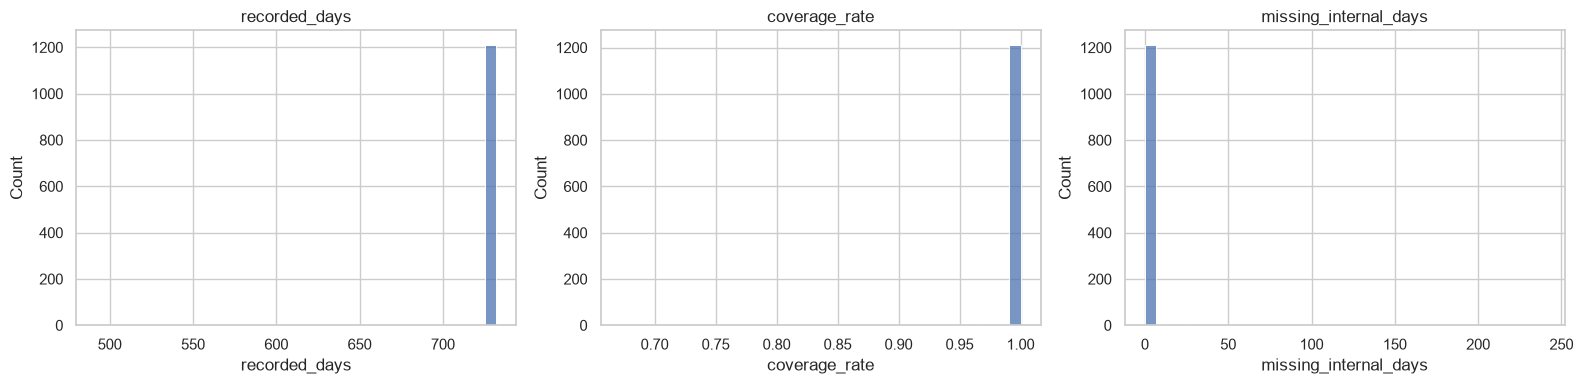

,observations
observed_state,
other_observed,879481
positive_stock_zero_sales,22957


Caution: end-of-day stock=0 with positive sales is possible; it is not necessarily an error.


In [7]:
d = df.sort_values(["product_id","date"]).copy()
coverage = d.groupby("product_id",observed=True).agg(first_date=("date","min"),last_date=("date","max"),recorded_days=("date","size"),total_sales=("sale_qty","sum"),observed_zero_sales=("sale_qty",lambda s:(s==0).sum()),observed_zero_stock=("stock_qty",lambda s:(s==0).sum()))
coverage["calendar_span_days"]=(coverage.last_date-coverage.first_date).dt.days+1
coverage["missing_internal_days"]=coverage.calendar_span_days-coverage.recorded_days
coverage["coverage_rate"]=coverage.recorded_days/coverage.calendar_span_days
coverage["observed_zero_sales_rate"]=coverage.observed_zero_sales/coverage.recorded_days
coverage["observed_zero_stock_rate"]=coverage.observed_zero_stock/coverage.recorded_days
print("Missing product-days within observed life:",f'{coverage.missing_internal_days.sum():,}')
print("Global dates:",d.date.nunique(),"full calendar days:",(d.date.max()-d.date.min()).days+1)
display(coverage.describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]).T)
fig,ax=plt.subplots(1,3,figsize=(16,4))
for a,c in zip(ax,["recorded_days","coverage_rate","missing_internal_days"]):sns.histplot(coverage[c],bins=35,ax=a);a.set_title(c)
plt.tight_layout();plt.show()

# Classify observed rows only; missing records are accounted separately above.
d["observed_state"] = np.select([d.sale_qty.isna() | d.stock_qty.isna(),d.stock_qty.eq(0)&d.sale_qty.gt(0),d.stock_qty.eq(0)&d.sale_qty.eq(0),d.stock_qty.gt(0)&d.sale_qty.eq(0)], ["missing_measurement","zero_end_stock_positive_sales","zero_stock_zero_sales","positive_stock_zero_sales"], default="other_observed")
display(d.observed_state.value_counts(dropna=False).to_frame("observations"))
print("Caution: end-of-day stock=0 with positive sales is possible; it is not necessarily an error.")

## 3. Temporal completeness and aggregate demand

Aggregate sales can be biased downward when fewer product-days are reported. Always examine active-product coverage alongside totals.

/tmp/ipykernel_3380637/2927229135.py:3: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  daily["weekday"]=daily.index.dayofweek


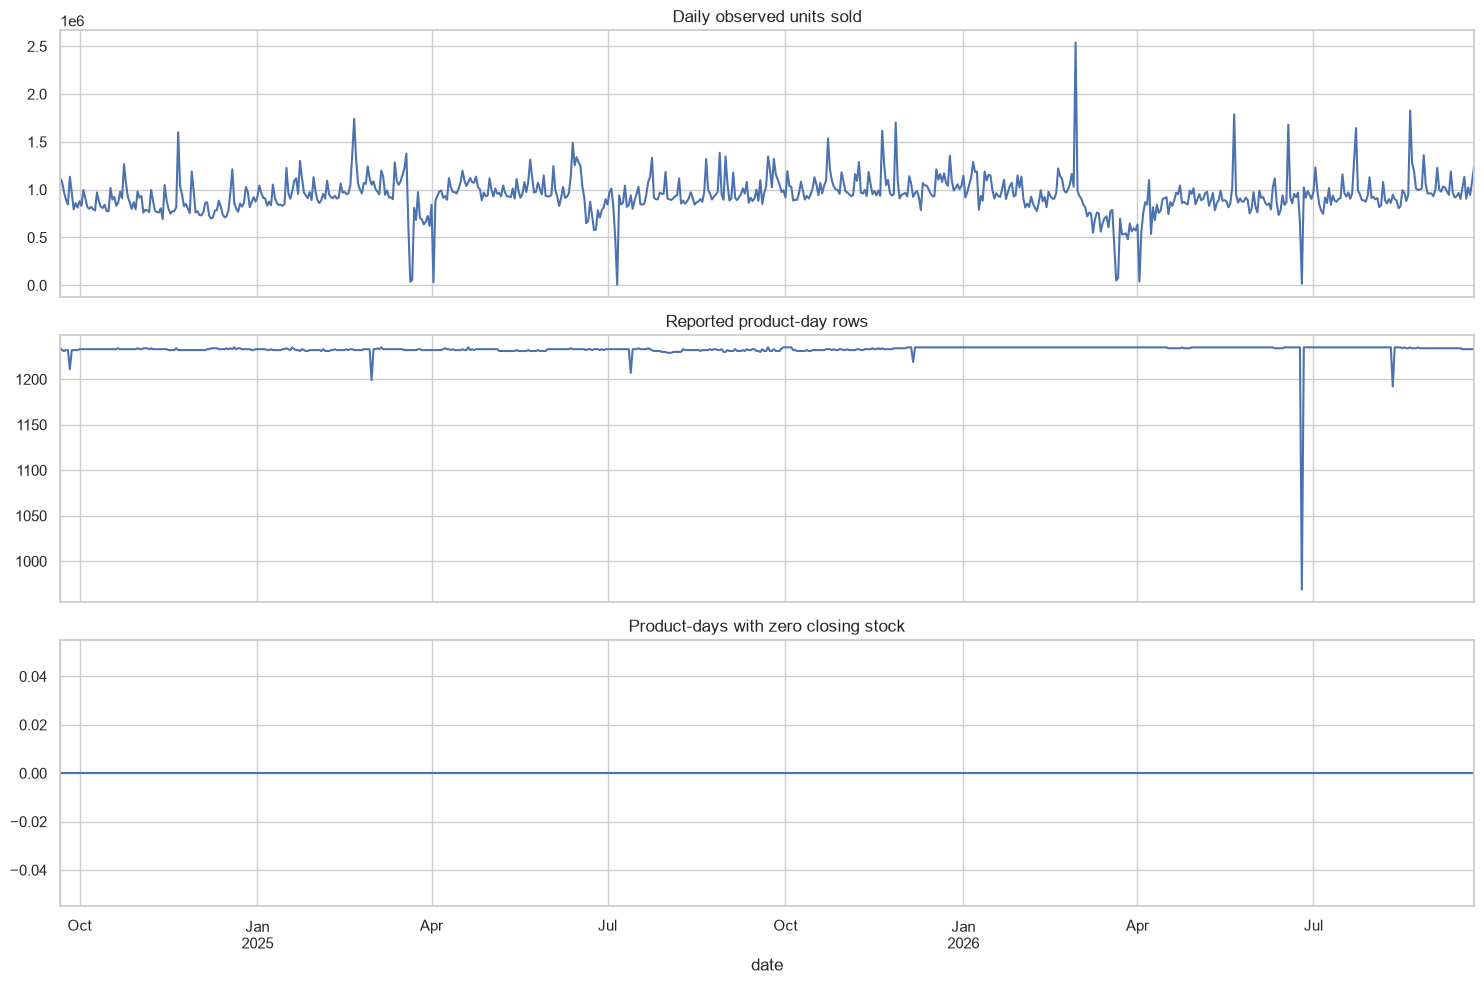

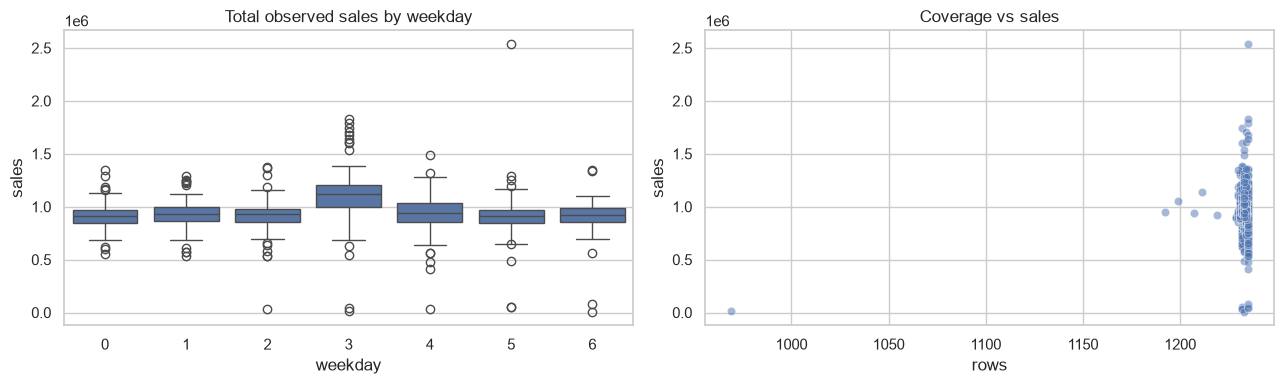

Unobserved dates globally: 0


In [8]:
daily = d.groupby("date",observed=True).agg(sales=("sale_qty","sum"),rows=("product_id","size"),selling_products=("sale_qty",lambda s:(s>0).sum()),stockout_products=("stock_qty",lambda s:(s==0).sum()),median_price=("price","median"))
daily=daily.asfreq("D")
daily["weekday"]=daily.index.dayofweek
fig,ax=plt.subplots(3,1,figsize=(15,10),sharex=True)
daily.sales.plot(ax=ax[0],title="Daily observed units sold");daily.rows.plot(ax=ax[1],title="Reported product-day rows");daily.stockout_products.plot(ax=ax[2],title="Product-days with zero closing stock");plt.tight_layout();plt.show()
fig,ax=plt.subplots(1,2,figsize=(13,4))
sns.boxplot(data=daily.reset_index(),x="weekday",y="sales",ax=ax[0]);ax[0].set_title("Total observed sales by weekday")
sns.scatterplot(data=daily.reset_index(),x="rows",y="sales",alpha=.5,ax=ax[1]);ax[1].set_title("Coverage vs sales")
plt.tight_layout();plt.show()
print("Unobserved dates globally:",int(daily.rows.isna().sum()))

## 4. Sales distribution, long tails and intermittent demand

Product-level ADI is computed from intervals between **positive sales on observed days**. Missing internal dates must be addressed before using textbook intermittency classifications. Here, intermittency is described with observed zero-sales fraction and daily demand variability.

,sale_qty
count,902438.0
mean,766.208696
std,1955.689855
min,0.0
1%,0.0
5%,3.92
25%,76.79
50%,247.06
75%,716.91
90%,1779.192


Observed zero-sales fraction: 2.54%


,count,mean,std,min,10%,25%,50%,75%,90%,95%,99%,max
days,1235.0,730.719028,10.396651,492.0,731.0,731.5,732.0,732.0,732.0,732.0,732.0,732.0
total,1235.0,559883.273636,1262110.759916,106.29,35810.046,79358.51,214446.66,533572.49,1303434.008,2077793.979,5251417.66,25144714.92
mean,1235.0,765.044744,1724.188842,0.216037,49.001517,108.413265,292.976731,728.924167,1780.647552,2838.516365,7174.067842,34350.703443
std,1235.0,411.771834,825.101147,0.776056,30.479835,64.072775,176.568632,400.119447,991.148964,1520.126027,3787.650651,13162.600222
nonzero_days,1235.0,712.130364,59.868332,76.0,664.4,729.0,731.0,732.0,732.0,732.0,732.0,732.0
positive_stock_days,1235.0,730.719028,10.396651,492.0,731.0,731.5,732.0,732.0,732.0,732.0,732.0,732.0
zero_fraction,1235.0,0.026075,0.078913,0.0,0.0,0.0,0.001366,0.004098,0.08559,0.175958,0.398137,0.845528
cv2,1235.0,0.620975,1.317511,0.047082,0.115559,0.177274,0.301867,0.628727,1.205391,1.913585,5.140707,26.942243
nonzero_interval_proxy,1235.0,1.042714,0.240325,1.0,1.0,1.0,1.001368,1.004115,1.093602,1.213533,1.661538,6.473684


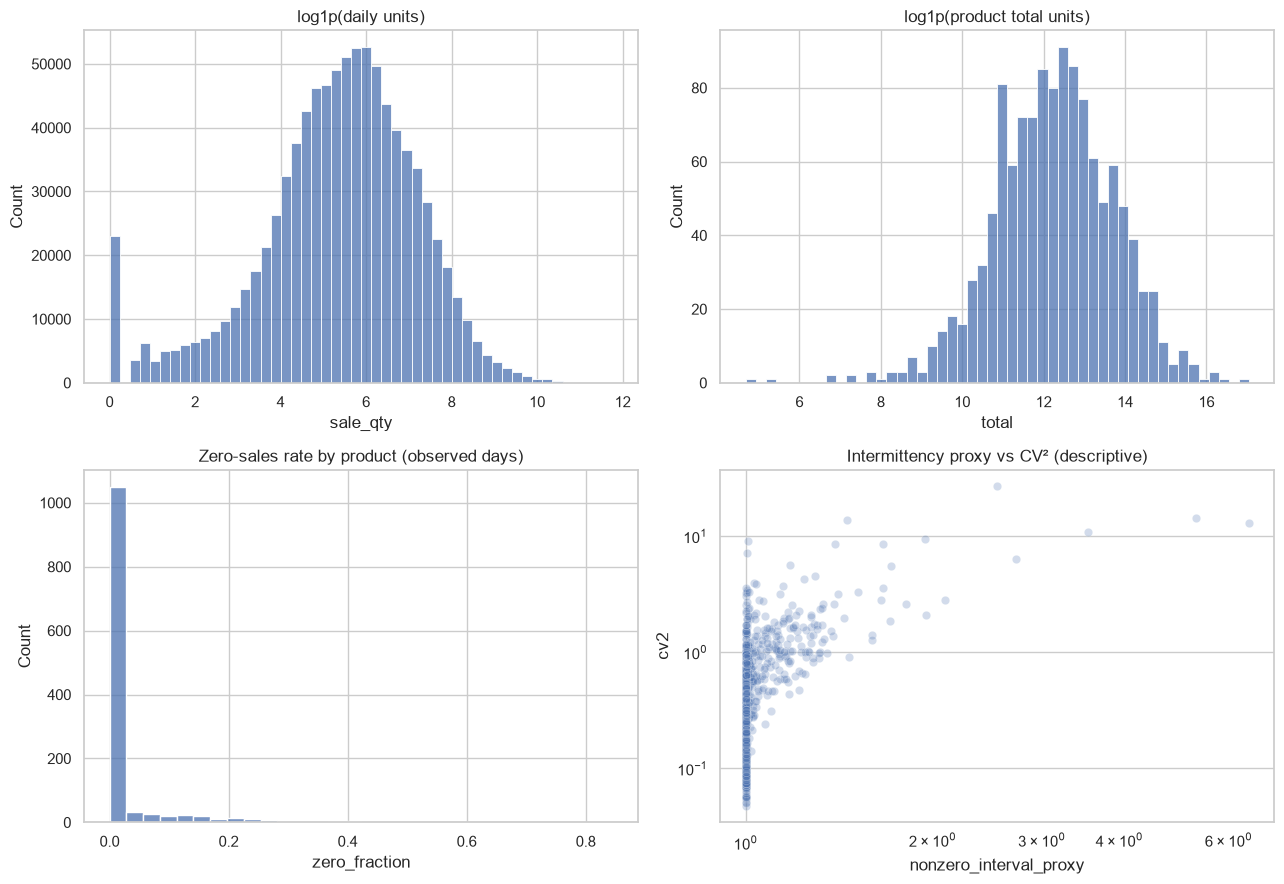

Top ten products by observed units:


,days,total,mean,std,nonzero_days,positive_stock_days,zero_fraction,cv2,nonzero_interval_proxy
product_id,,,,,,,,,
P_0402,732,25144714.92,34350.703443,13162.600222,732,732,0.0,0.146829,1.0
P_0176,732,14881761.16,20330.274809,11059.393289,731,732,0.001366,0.295921,1.001368
P_0062,732,10925097.06,14924.995984,3368.877644,732,732,0.0,0.05095,1.0
P_0070,732,10785908.36,14734.847486,4418.354186,732,732,0.0,0.089915,1.0
P_0061,732,10603350.68,14485.451749,5223.387508,732,732,0.0,0.130029,1.0
P_0432,732,8366454.42,11429.582541,4452.969635,732,732,0.0,0.151788,1.0
P_0798,732,6306012.69,8614.771434,3057.110745,732,732,0.0,0.125932,1.0
P_0055,732,6181835.03,8445.129822,3586.982797,732,732,0.0,0.180404,1.0
P_0218,732,6094247.67,8325.474959,2620.671597,732,732,0.0,0.099085,1.0


In [9]:
sales=d.sale_qty.dropna()
display(sales.describe(percentiles=[.01,.05,.25,.5,.75,.9,.95,.99,.999]).to_frame("sale_qty"))
print("Observed zero-sales fraction:",f"{d.sale_qty.eq(0).mean():.2%}")
prod=d.groupby("product_id").agg(days=("date","size"),total=("sale_qty","sum"),mean=("sale_qty","mean"),std=("sale_qty","std"),nonzero_days=("sale_qty",lambda x:(x>0).sum()),positive_stock_days=("stock_qty",lambda x:(x>0).sum()))
prod["zero_fraction"]=1-prod.nonzero_days/prod.days
prod["cv2"]=(prod["std"]/prod["mean"].replace(0,np.nan))**2
prod["nonzero_interval_proxy"]=prod.days/prod.nonzero_days.replace(0,np.nan)
display(prod.describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]).T)
fig,ax=plt.subplots(2,2,figsize=(13,9))
sns.histplot(np.log1p(sales.clip(lower=0)),bins=50,ax=ax[0,0]);ax[0,0].set_title("log1p(daily units)")
sns.histplot(np.log1p(prod.total.clip(lower=0)),bins=50,ax=ax[0,1]);ax[0,1].set_title("log1p(product total units)")
sns.histplot(prod.zero_fraction,bins=30,ax=ax[1,0]);ax[1,0].set_title("Zero-sales rate by product (observed days)")
sns.scatterplot(data=prod,x="nonzero_interval_proxy",y="cv2",alpha=.25,ax=ax[1,1]);ax[1,1].set(xscale="log",yscale="log",title="Intermittency proxy vs CV² (descriptive)")
plt.tight_layout();plt.show()
print("Top ten products by observed units:");display(prod.nlargest(10,"total"))

## 5. Potential spikes and anomalies (flag, do not delete)

A robust per-product upper-tail rule marks possible peaks. Spikes can be genuine promotional/calendar effects, recording errors, or stock-driven events. No rows are removed. Median/MAD rules can degenerate for sparse demand, so quantile fallback is used.

In [10]:
g=d.groupby("product_id")["sale_qty"]
med=g.transform("median");mad=g.transform(lambda s:(s-s.median()).abs().median())
q99=g.transform(lambda s:s.quantile(.99))
spike=(d.sale_qty>med+6*1.4826*mad)&(d.sale_qty>0)&(mad>0)
spike |= (mad.eq(0)&d.sale_qty.gt(q99)&d.sale_qty.gt(0))
d["spike_flag_eda"]=spike
print("Spike-flag rows:",int(spike.sum()),"fraction:",f"{spike.mean():.2%}")
display(d.loc[spike,["date","product_id","sale_qty","stock_qty","price","discount_pct"]].sort_values("sale_qty",ascending=False).head(25))
print("Spike shares on zero closing-stock days:",round(d.loc[spike,"stock_qty"].eq(0).mean(),3) if spike.sum() else np.nan)
print("Spike shares on discounted days:",round(d.loc[spike,"discount_pct"].gt(0).mean(),3) if spike.sum() else np.nan)

Spike-flag rows: 12464 fraction: 1.38%


,date,product_id,sale_qty,stock_qty,price,discount_pct
293527,2026-08-20,P_0402,129289.62,714779.12,1753870.0,25.1
293261,2025-11-27,P_0402,103551.67,661587.98,927671.0,27.4
293436,2026-05-21,P_0402,98732.66,528578.66,1724463.0,25.1
293464,2026-06-18,P_0402,95405.29,643269.34,1739300.0,22.9
622191,2026-02-28,P_0852,94577.62,403563.17,1966133.0,16.0
293135,2025-07-24,P_0402,91577.13,461891.91,909165.0,27.7
293226,2025-10-23,P_0402,91378.96,516498.35,927654.0,28.8
293541,2026-09-03,P_0402,86867.93,600495.5,1911883.0,27.3
292981,2025-02-20,P_0402,83974.38,623216.71,757727.0,32.5
622364,2026-08-20,P_0852,68318.38,270302.18,3406392.0,40.6


Spike shares on zero closing-stock days: 0.0
Spike shares on discounted days: 0.976


## 6. Stock, availability, sales censoring

`stock_qty` is end-of-day, not beginning-of-day inventory. Thus, 0 closing stock alone cannot prove that sales were constrained throughout that day. `num_stores_with_stock` indicates distribution coverage but may itself be measured at day's end. Treat both as historical contextual signals.


 stock_qty


,stock_qty
count,902438.0
mean,17094.031183
std,30930.743615
min,0.6
1%,18.24
10%,881.834
25%,3396.49
50%,8505.76
75%,18981.33
90%,38521.033



 num_stores_with_stock


,num_stores_with_stock
count,902438.0
mean,209.002292
std,101.443984
min,0.0
1%,2.0
10%,38.0
25%,136.0
50%,237.0
75%,286.0
90%,324.0



 price


,price
count,902438.0
mean,1636460.115068
std,2081929.912503
min,0.0
1%,0.0
10%,223743.0
25%,441220.0
50%,908701.5
75%,2003155.0
90%,3919881.2



 discount_pct


,discount_pct
count,902438.000000
mean,9.869318
std,8.159821
min,0.000000
1%,0.000000
10%,0.900000
25%,2.800000
50%,8.700000
75%,14.800000
90%,20.700000


Zero stock with positive sales: 0
Positive stock with zero sales: 22957
Store-stock contradictions (zero stock, >0 stores): 0
Store-stock contradictions (positive stock, 0 stores): 2635


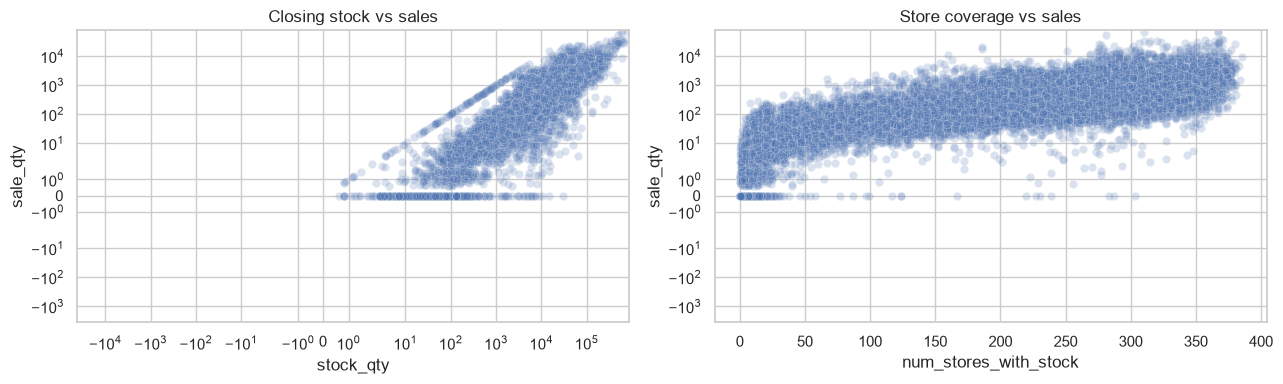

In [11]:
for c in ["stock_qty","num_stores_with_stock","price","discount_pct"]:
 print("\n",c);display(d[c].describe(percentiles=[.01,.1,.25,.5,.75,.9,.95,.99]).to_frame())
print("Zero stock with positive sales:",int(((d.stock_qty==0)&(d.sale_qty>0)).sum()))
print("Positive stock with zero sales:",int(((d.stock_qty>0)&(d.sale_qty==0)).sum()))
print("Store-stock contradictions (zero stock, >0 stores):",int(((d.stock_qty==0)&(d.num_stores_with_stock>0)).sum()))
print("Store-stock contradictions (positive stock, 0 stores):",int(((d.stock_qty>0)&(d.num_stores_with_stock==0)).sum()))
fig,ax=plt.subplots(1,2,figsize=(13,4))
sns.scatterplot(data=d.sample(min(len(d),20000),random_state=42),x="stock_qty",y="sale_qty",alpha=.2,ax=ax[0]);ax[0].set(xscale="symlog",yscale="symlog",title="Closing stock vs sales")
sns.scatterplot(data=d.sample(min(len(d),20000),random_state=42),x="num_stores_with_stock",y="sale_qty",alpha=.2,ax=ax[1]);ax[1].set(yscale="symlog",title="Store coverage vs sales")
plt.tight_layout();plt.show()

## 7. Pricing, discounts and within-product changes

Cross-sectional price–sales correlations are confounded by product identity and category. This section visualizes variation but does **not** estimate causal price elasticity.

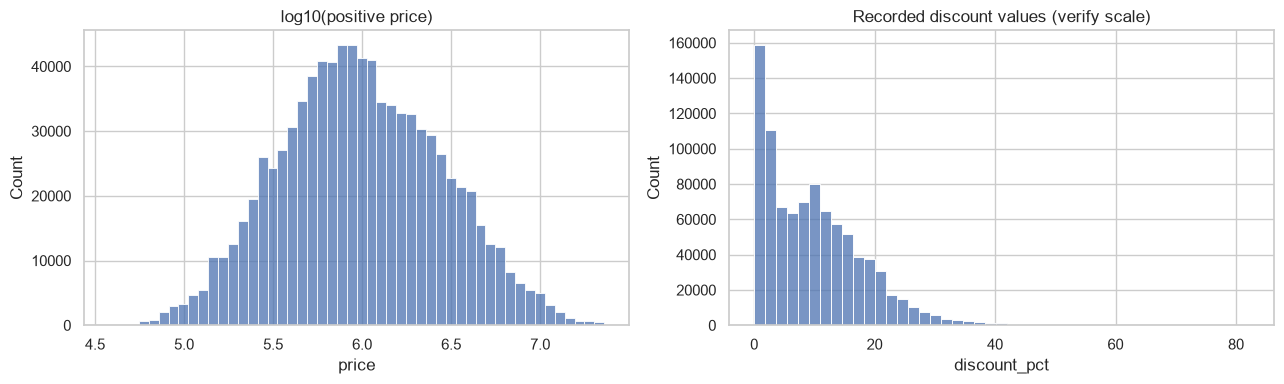

Price change frequency on consecutive observed records: 0.8149
Discount change frequency: 0.9663


,count,mean,std,min,25%,50%,75%,90%,99%,max
unique_prices,1235.0,516.244534,166.974144,2.0,428.0,567.0,642.5,688.0,727.0,732.0
unique_discounts,1235.0,189.304453,52.821245,45.0,155.0,195.0,227.0,254.0,295.0,329.0


Same-day sales by discount bucket (descriptive; not causal):


,observations,mean_sales,median_sales
discount_pct,,,
"(-0.001, 1.3]",119957,377.118117,91.79
"(1.3, 2.8]",108374,542.438566,205.59
"(2.8, 5.5]",111652,635.736801,219.44
"(5.5, 8.7]",113189,716.304279,225.78
"(8.7, 11.3]",113071,821.583003,262.15
"(11.3, 14.8]",112205,870.01711,296.78
"(14.8, 19.6]",113145,980.853624,345.06
"(19.6, 82.2]",110845,1207.780528,396.25


In [12]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
sns.histplot(d.loc[d.price.gt(0),"price"].pipe(np.log10),bins=50,ax=ax[0]);ax[0].set_title("log10(positive price)")
sns.histplot(d.discount_pct.dropna(),bins=45,ax=ax[1]);ax[1].set_title("Recorded discount values (verify scale)")
plt.tight_layout();plt.show()
d["price_changed"] = d.groupby("product_id").price.diff().ne(0)
d["discount_changed"] = d.groupby("product_id").discount_pct.diff().ne(0)
first_obs = d.groupby("product_id").cumcount().eq(0)
d.loc[first_obs,["price_changed","discount_changed"]]=False
print("Price change frequency on consecutive observed records:",round(d.price_changed.mean(),4))
print("Discount change frequency:",round(d.discount_changed.mean(),4))
product_prices=d.groupby("product_id").agg(unique_prices=("price","nunique"),unique_discounts=("discount_pct","nunique"))
display(product_prices.describe(percentiles=[.25,.5,.75,.9,.99]).T)
print("Same-day sales by discount bucket (descriptive; not causal):")
if d.discount_pct.notna().any():
    display(d.groupby(pd.qcut(d.discount_pct, q=min(8,d.discount_pct.nunique()),duplicates="drop"),observed=True).agg(observations=("sale_qty","size"),mean_sales=("sale_qty","mean"),median_sales=("sale_qty","median")))

## 8. Category hierarchy, brand structure and substitute-group feasibility

The task explicitly calls for competition features among products in a category group (e.g., Level4). Check hierarchical stability, category sizes, and number of co-present alternatives before defining substitution groups.

Cardinalities and missingness:


,distinct,missing_pct
Level1,5,0.0
Level2,25,0.0
Level3,49,0.0
Level4,88,0.0
Level5,289,0.0
brand_id,234,0.0


Products whose Level1 changes over time: 0
Products whose Level2 changes over time: 0
Products whose Level3 changes over time: 0
Products whose Level4 changes over time: 0
Products whose Level5 changes over time: 0
Products whose brand_id changes over time: 0
Level2 nodes with multiple Level1 parents: 0 (IDs may be reused across branches)
Level3 nodes with multiple Level2 parents: 0 (IDs may be reused across branches)
Level4 nodes with multiple Level3 parents: 0 (IDs may be reused across branches)
Level5 nodes with multiple Level4 parents: 0 (IDs may be reused across branches)

Level4 products per group:


,product_id
count,88.000000
mean,14.034091
std,11.378997
min,2.000000
10%,4.000000
25%,6.000000
50%,10.000000
75%,17.250000
90%,36.000000
99%,47.260000


Daily co-present products per group:


,product_id
count,64416.000000
mean,14.009532
std,11.310576
min,1.000000
25%,6.000000
50%,10.000000
75%,17.000000
90%,36.000000
99%,49.000000
max,49.000000


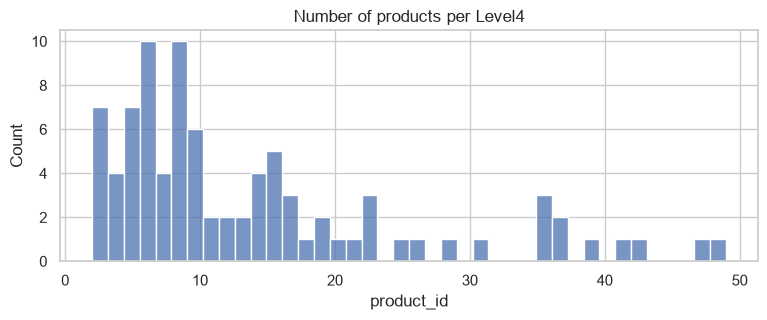


Level5 products per group:


,product_id
count,289.000000
mean,4.273356
std,3.991921
min,1.000000
10%,1.000000
25%,2.000000
50%,3.000000
75%,6.000000
90%,9.000000
99%,17.120000


Daily co-present products per group:


,product_id
count,211473.000000
mean,4.267391
std,3.982527
min,1.000000
25%,2.000000
50%,3.000000
75%,6.000000
90%,9.000000
99%,18.000000
max,34.000000


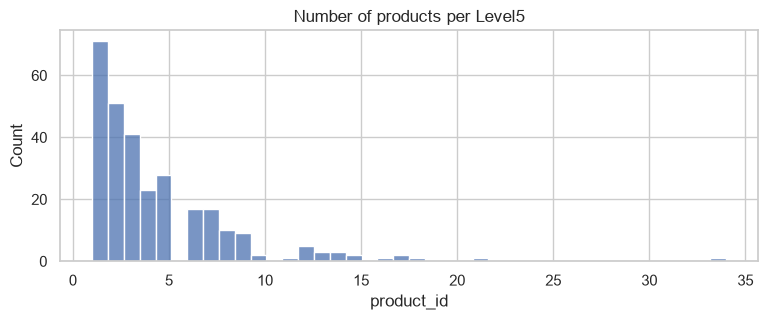

In [13]:
cats=["Level1","Level2","Level3","Level4","Level5","brand_id"]
print("Cardinalities and missingness:");display(pd.DataFrame({"distinct":d[cats].nunique(),"missing_pct":100*d[cats].isna().mean()}))
for level in ["Level1","Level2","Level3","Level4","Level5","brand_id"]:
    inconsistent=(d.groupby("product_id")[level].nunique(dropna=True)>1)
    print(f"Products whose {level} changes over time: {inconsistent.sum():,}")
for parent,child in zip(cats[:4],cats[1:5]):
    nonnested=(d.groupby(child,dropna=True)[parent].nunique(dropna=True)>1)
    print(f"{child} nodes with multiple {parent} parents: {nonnested.sum():,} (IDs may be reused across branches)")
for level in ["Level4","Level5"]:
    group_size=d.groupby(level)["product_id"].nunique()
    print(f"\n{level} products per group:");display(group_size.describe(percentiles=[.1,.25,.5,.75,.9,.99]).to_frame())
    date_group=d.groupby(["date",level],observed=True).product_id.nunique()
    print("Daily co-present products per group:");display(date_group.describe(percentiles=[.25,.5,.75,.9,.99]).to_frame())
    fig,ax=plt.subplots(figsize=(9,3));sns.histplot(group_size,bins=40,ax=ax);ax.set_title(f"Number of products per {level}");plt.show()

## 9. Recency, product life cycle, calendar and history-window readiness

Compare 30/60/90/180-day historical coverage without producing model inputs. A product with insufficient history may need category pooling. Holidays cannot be assumed known without geographic/business calendar context.

Last  30 days: present products=1,235; >=80% coverage=1,233; >=50% coverage=1,234
Last  60 days: present products=1,235; >=80% coverage=1,234; >=50% coverage=1,234
Last  90 days: present products=1,235; >=80% coverage=1,234; >=50% coverage=1,235
Last 180 days: present products=1,235; >=80% coverage=1,234; >=50% coverage=1,235
Last 365 days: present products=1,235; >=80% coverage=1,235; >=50% coverage=1,235


,sales,rows,sales_per_row
date,,,
2024-10-01,27495268.11,38225,719.30067
2024-11-01,26251622.86,36981,709.867847
2024-12-01,25746010.81,38226,673.520923
2025-01-01,29964498.02,38205,784.308285
2025-02-01,29056355.29,34501,842.188786
2025-03-01,27596435.19,38180,722.798198
2025-04-01,29128417.01,36978,787.72289
2025-05-01,31165781.96,38176,816.37107
2025-06-01,28401460.22,36987,767.876828


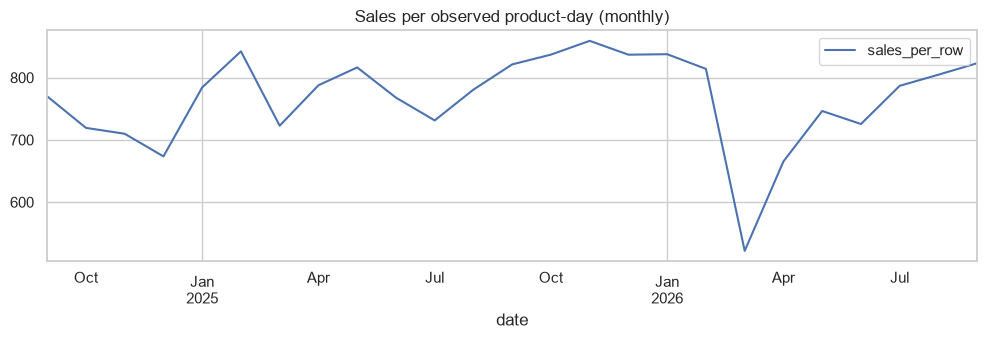

Data horizon days: 732
Observed product count by first month:


,products_first_seen
first_date,
2024-09,1234
2024-11,1


In [14]:
last=d.date.max()
for lookback in [30,60,90,180,365]:
    window=d[d.date.between(last-pd.Timedelta(days=lookback-1),last)]
    observed_per_product=window.groupby("product_id").size()
    print(f"Last {lookback:3} days: present products={observed_per_product.size:,}; >=80% coverage={(observed_per_product>=.8*lookback).sum():,}; >=50% coverage={(observed_per_product>=.5*lookback).sum():,}")
monthly=d.groupby(pd.Grouper(key="date",freq="MS")).agg(sales=("sale_qty","sum"),rows=("product_id","size"))
monthly["sales_per_row"]=monthly.sales/monthly.rows.replace(0,np.nan)
display(monthly.tail(24))
monthly[["sales_per_row"]].plot(figsize=(12,3),title="Sales per observed product-day (monthly)");plt.show()
print("Data horizon days:",(last-d.date.min()).days+1)
print("Observed product count by first month:")
display(coverage.first_date.dt.to_period("M").value_counts().sort_index().tail(18).to_frame("products_first_seen"))

## 10. EDA synthesis: diagnostic summary

This summary reports empirical facts from the loaded data; interpretation should distinguish recording artifacts from demand behavior. No future-looking features are computed.

In [15]:
report=pd.Series({
"rows":len(d),"products":d.product_id.nunique(),"dates_observed":d.date.nunique(),"calendar_days_global":(d.date.max()-d.date.min()).days+1,
"internal_missing_product_days":int(coverage.missing_internal_days.sum()),
"products_with_internal_gaps":int(coverage.missing_internal_days.gt(0).sum()),
"median_product_recorded_days":float(coverage.recorded_days.median()),
"observed_zero_sale_fraction":float(d.sale_qty.eq(0).mean()),
"observed_zero_closing_stock_fraction":float(d.stock_qty.eq(0).mean()),
"sales_positive_with_zero_closing_stock":int(((d.sale_qty>0)&(d.stock_qty==0)).sum()),
"spike_flagged_rows":int(d.spike_flag_eda.sum()),
"products_with_multiple_prices":int(product_prices.unique_prices.gt(1).sum()),
"products_with_multiple_discounts":int(product_prices.unique_discounts.gt(1).sum()),
})
display(report.to_frame("value"))
print("EDA COMPLETE. Next: discuss handling decisions, competitive feature design, time-based backtesting and model choices. No modeling performed.")

,value
rows,902438.000000
products,1235.000000
dates_observed,732.000000
calendar_days_global,732.000000
internal_missing_product_days,1499.000000
products_with_internal_gaps,309.000000
median_product_recorded_days,732.000000
observed_zero_sale_fraction,0.025439
observed_zero_closing_stock_fraction,0.000000
sales_positive_with_zero_closing_stock,0.000000


EDA COMPLETE. Next: discuss handling decisions, competitive feature design, time-based backtesting and model choices. No modeling performed.


## 11. Forecasting contract and preprocessing policy

**Status:** Working decisions following the EDA, recorded on 2026-10-25. This section documents the agreed contract. Section 12 implements preprocessing, feature extraction and complete targets under that contract. Existing EDA outputs are retained; no predictive model is trained.

### Forecast definition and information cutoff

- Predict each product's **observed sales total over the next 30 calendar days**. The target is realized sales under actual availability, rather than unobserved unconstrained demand.
- Let `T` be the last fully closed and available business date. Forecast after its daily data load has completed, using historical observations dated at or before `T`.
- The target interval is **`T + 1` through `T + 30`, inclusive**. The initial 90-day history interval is **`T - 89` through `T`, inclusive**.
- End-of-day stock and realized sales/price/discount for `T` are historical inputs only if that day's load is complete. If daily reporting has a delay, move the effective information cutoff backward by that delay. Never assume same-day values are available before closing.
- Keep both the Gregorian date used for chronological operations and the original Jalali date used to identify the business calendar. Do not infer a specific time-of-day timezone from date-only records.
- Future-known inputs are calendar dates and verified calendar events. The file supplies no future price, discount, inventory, replenishment, store-availability, or competitor plans; treat those quantities as unknown beyond `T`.
- The requested product set is the products known by `T`. Future appearance, disappearance, or future category membership cannot determine the forecasting cohort.

**Initial experiment cohort:** At least 90 calendar days since first observation, at least **86 observed days in the last 90 days** (95% coverage rounded upward), and at least one observation in the final seven days. Eligibility uses historical availability only. Products outside this cohort remain forecast requests and require a separately identified fallback route; they are not assigned zero demand or assumed discontinued. Baseline and main-model comparisons must use the same eligible products at each origin.

### Missing records and measurement handling

The source has zero null values and zero globally absent dates. It still has **1,499 missing product-day rows within observed product lifetimes**, across 525 missing runs; 426 runs last one day and the longest lasts 64 days. This mixture does not support a blanket zero-fill or interpolation policy.

| Situation | Working decision |
|---|---|
| An observed `sale_qty == 0` | Preserve a genuine recorded zero. |
| An absent product-day row | Represent an unknown observation in the calendar-aligned working view; do not fabricate zero sales, stock, price, or discount. |
| A historical gap | Preserve it. Any later summary must expose its observed-day count, calendar-day count, coverage, and staleness. |
| Product boundaries | Do not fill before the first record or after the last record as if introduction/discontinuation were known. At a historical cutoff, do not use a product's eventual last date to infer its current status. |
| Unknown future sales within a 30-day label interval | Do not produce a partial sum labeled as a full 30-day target. Require 30 recorded, valid daily sales values for training and primary evaluation. |
| Fractional sales or stock | Preserve floating-point values. Their prevalence does not justify rounding or a count-only interpretation. |
| Zero discount | Preserve zero as a valid recorded discount; do not treat it as missing or forward-fill it. |
| Sales spikes and unexplained sales collapses | Preserve raw sales in the primary analysis. Flag for investigation; no automatic clipping, replacement, or removal. |

For later historical summaries, distinguish `sum_observed_sales` from a complete-calendar sum. A mean computed over observed days must use the observed-day denominator. A rate multiplied by 30 is an explicit forecasting assumption, not recovered historical data. Avoid scaling incomplete future targets to 30 days: the missingness may be related to operations or demand.

Label completeness is checked only to establish whether an outcome can be measured. It is not an input feature or an inference-time eligibility rule. Report exclusions by origin and product segment, because complete-label evaluation can favor better-recorded products.

Do not standardize or alter the raw units at this stage. Any later fitted imputation, scaling, clipping threshold, target encoding, or anomaly-reference statistic must be learned within each training fold. The current full-history spike diagnostic remains EDA-only.

### Price and stock assumptions for the modeling view

These are conservative operating assumptions. The dataset cannot prove the exact price construction, distinguish warehouse stock from store stock, or recover unobserved lost sales. Those limitations remain documented rather than being presented as resolved facts.

**Price**

- All 22,957 recorded zero-price rows are also zero-sales rows, and the reverse holds. Treat zero recorded price as **unknown usable price**, not as evidence that a free offer existed. Preserve the raw field and a zero-price indicator.
- A last positive recorded price may be carried forward **as a last-known historical measurement**, with its observation date and age. It must not be labeled the actual current offer price or a future price plan.
- Never backward-fill from a later positive price, interpolate using future observations, or use the next observed price to repair a zero-price day.
- If no positive price has been observed by the cutoff, retain unknown. The audit finds 86 zero-price rows with no preceding positive recorded price.
- Among zero-price rows with a preceding positive price, the median age is 3 days, the 95th percentile is 30 days, and the maximum is 106 days. A stale observation should remain explicitly stale, rather than being treated as freshly observed.
- Historical discounts remain recorded historical measurements on a 0-100 percentage-point scale. Neither price nor discount is assumed known for the forecast horizon.

**Stock and store availability**

- Interpret `stock_qty` as end-of-day inventory, following the task dictionary. It is not beginning-of-day supply, intraday stockout duration, replenishment, or unconstrained demand.
- In every observed row, closing stock is at least the day's sales. In 6,194 rows the quantities are equal. In particular, every reported product has equality on these dates:

| Date | Reported products | Products with `stock_qty == sale_qty` |
|---|---:|---:|
| 2024-09-26 | 1,211 | 1,211 |
| 2025-03-01 | 1,199 | 1,199 |
| 2025-12-06 | 1,219 | 1,219 |
| 2026-06-25 | 969 | 969 |
| 2026-08-11 | 1,192 | 1,192 |

- Preserve these raw measurements, but flag row-level equality as suspect. For the initial modeling view, exclude equality rows from inventory-quantity summaries while retaining the associated sales observations and their quality flags. Equality is a conservative quality rule, not proof that every such individual measurement is wrong.
- Preserve zero recorded store counts. Flag positive-stock/zero-store disagreement rather than silently converting either field: 2,635 rows disagree, and 519 of them have positive sales. The source does not establish whether inventory locations and store counts share identical scope or timing.
- Do not divide by zero store counts, infer exact stockout days from this file, or replace observed sales with estimated lost sales.
- Compare the conservative inventory view against raw historical stock in a later ablation. No stock values from the forecast horizon may enter either version.

Suspect inventory is handled separately from sales truth. Until a reporting error is established, retain observed sales on suspect dates in the primary targets, identify affected evaluation windows, and report sensitivity separately. Excluding a suspect predictor does not authorize erasing its observed sales outcome.

### Evaluation cutoffs and completeness audit

Reserve the last fully observable 30-day horizon for the final test. Use the three preceding, nonoverlapping 30-day horizons for development backtests. Retrain at each origin using information available by that origin.

| Role | Forecast origin `T` | Target interval | Products with complete 30-day sales | Products also meeting the initial history rule |
|---|---|---|---:|---:|
| Development fold 1 | 2026-05-25 | 2026-05-26 to 2026-06-24 | 1,234 | 1,233 |
| Development fold 2 | 2026-06-24 | 2026-06-25 to 2026-07-24 | 969 | 968 |
| Development fold 3 | 2026-07-24 | 2026-07-25 to 2026-08-23 | 1,192 | 1,191 |
| Final test | 2026-08-23 | 2026-08-24 to 2026-09-22 | 1,233 | 1,232 |

These are eligibility counts computed directly from date presence, not constructed training labels or modeling results. There are 1,235 known products at each listed origin. The second development fold has incomplete outcomes for 266 products, demonstrating why absent future records cannot safely be filled with zero. Report each fold separately and report the number and historical volume share of excluded products; a single pooled score would conceal changes in evaluation coverage.

For a fold with origin `T`, a training sample with origin `t` is permitted only if **`t + 30 <= T`** and its target is complete. Its own historical inputs must end at `t`. This prevents overlapping training labels from reaching into the validation horizon. Do not random-split product-origin rows. Overlapping labels within the training set are possible, but they do not justify cross-boundary overlap or treating the samples as independent in uncertainty estimates.

Tune history length, feature sets, and other decisions using development folds only. Fit the final model with the chosen settings using labels available by 2026-08-23, then evaluate the reserved final horizon once. Compare alternative history windows using a common eligible cohort at each origin.

**Implementation:** Section 12 implements calendar alignment, observation masks, measurement-quality handling, historical and competitive features, complete 30-day labels, and cutoff-safe split indexes. The baseline/main-model experiment remains subsequent work.

## 12. Preprocessing and feature extraction

This section runs the reusable implementation in `src/okala/features.py`. Each row represents one product at an end-of-day forecast origin. All product measurements and category membership are taken at or before that origin; only calendar dates may extend into the future.

The code below is self-contained: it reloads the source without importing the full-history spike flags from EDA. Raw data are not overwritten. Features and future targets are exported separately, with an explicit model-input whitelist.

| Proposed feature family | Implemented examples |
|---|---|
| Main features | Product, brand, hierarchy, last observed sales, last known positive price, usable stock, recorded discount and store coverage |
| Aggregated / historical compression | Observed and complete sums, means, standard deviations, medians, extrema, and calendar-decayed means |
| Difference / deviation | Sales z-score and deviation, short/long sales-rate comparison, price deviation and discount deviation |
| Handcrafted / domain | Historical sales per stocked store, inventory-cover proxy, intermittency proxy, named Jalali date counts |
| Temporal | 7/14/30/60/90/180-day summaries, exact-day sales lags through 364 days, positive/zero/discounted-day counts and rates |
| Missingness and metadata | Coverage, gaps and gap runs, time since measurement, price staleness, zero-price and suspicious-stock flags |
| Velocity and acceleration / fractional trends | Disjoint weekly rates, fractional velocity and acceleration, daily first/second differences, price/store changes |
| Higher-order statistics | Skewness, excess kurtosis, IQR, tail spread, CV, positive-sales CV², normalized sales-share entropy, top-day concentration |
| Cyclical / spatial transformations | Weekday and Jalali seasonal sine/cosine; future horizon calendar composition. Spatial transforms are unavailable because no coordinates/store identities are supplied. |
| Competition | 14 peer features covering relative prices, discount gaps, availability, reporting coverage, historical shares and peer sales trends |

These families overlap conceptually; each column is assigned one primary family in the catalog. This is a candidate feature set to evaluate, not a claim that every feature improves a model.

In [16]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

from okala.features import FeatureConfig, RetailFeaturePipeline, export_artifacts, split_for_origin

FEATURE_DATA_PATH = DATA_PATH
FEATURE_OUTPUT_DIR = PROJECT_ROOT / "data/processed"
feature_config = FeatureConfig()
feature_pipeline = RetailFeaturePipeline(pd.read_parquet(FEATURE_DATA_PATH), feature_config)
display(feature_pipeline.quality_report())
print("Raw zero sales are retained. Gaps are unknown. Positive stock=sales is masked only in the usable inventory view.")
print("Configuration:", feature_config)

,count
source_rows,902438
products,1235
calendar_days,732
null_source_values,0
globally_absent_dates,0
internal_missing_product_days,1499
zero_price_measurements,22957
masked_inventory_measurements,6194
stock_store_disagreements,2635


Raw zero sales are retained. Gaps are unknown. Positive stock=sales is masked only in the usable inventory view.
Configuration: FeatureConfig(windows=(7, 14, 30, 60, 90, 180), horizon_days=30, history_days=90, min_history_coverage=0.95, recency_days=7, competition_level='Level4', peer_price_max_age_days=30, min_moment_observations=8)


### Inspect a snapshot and its definitions

The latest origin produces inference features even though its next 30 days are not in the file. Last-known price and inventory values have explicit ages. Peer prices older than 30 days are excluded from relative-price comparisons. Relative prices use the source price units; package-size normalization is unavailable.

New feature NaNs are intentional: an unknown historical day, an undefined zero-denominator growth rate, a singleton peer group, insufficient variance/history, or an absent verified holiday calendar must not become a fabricated zero. Higher-order moments require at least eight observed days and positive variance.

In [17]:
latest_origin = feature_pipeline.dates[-1]
latest_features = feature_pipeline.features_at(latest_origin)
feature_catalog = feature_pipeline.catalog
feature_columns = feature_pipeline.model_feature_columns

family_summary = (
    feature_catalog[feature_catalog.role.eq("feature")]
    .groupby("family").size().rename("feature_count").to_frame()
)
display(family_summary)
print(f"Latest origin: {latest_origin.date()} | products: {len(latest_features):,} | model features: {len(feature_columns)}")
print("History-eligible:", int(latest_features.history_eligible.sum()))
display(latest_features[[
    "forecast_origin", "product_id", "sales_mean_7d", "sales_mean_30d",
    "price_positive_last_observed", "price_positive_age_days",
    "relative_price_vs_peer_median", "discount_gap_vs_peers_pp",
    "sales_weekly_fractional_velocity", "sales_weekly_fractional_acceleration",
    "sales_skewness_30d", "sales_normalized_entropy_30d", "history_eligible"
]].head(8))
display(feature_catalog[feature_catalog.family.eq("competition")][
    ["name", "definition", "availability", "lookback_days"]
])

,feature_count
family,
aggregated,62
competition,14
cyclical,27
deviation,5
domain,7
higher_order,16
main,12
missingness_metadata,43
temporal,23


Latest origin: 2026-09-22 | products: 1,235 | model features: 215
History-eligible: 1233


,forecast_origin,product_id,sales_mean_7d,sales_mean_30d,price_positive_last_observed,price_positive_age_days,relative_price_vs_peer_median,discount_gap_vs_peers_pp,sales_weekly_fractional_velocity,sales_weekly_fractional_acceleration,sales_skewness_30d,sales_normalized_entropy_30d,history_eligible
0,2026-09-22,P_0001,947.478571,850.342667,1671694.0,0.0,1.611359,-0.984783,0.214865,0.224173,3.126887,0.994412,True
1,2026-09-22,P_0002,76.078571,115.854333,1259622.0,0.0,1.124658,-2.240000,-0.199269,-0.005935,0.871675,0.983694,True
2,2026-09-22,P_0003,465.042857,441.316333,1514130.0,0.0,1.162763,-0.869231,0.537811,0.963167,1.156890,0.982703,True
3,2026-09-22,P_0004,42.584286,43.861667,10967374.0,0.0,8.422299,-4.853846,0.152217,0.295675,0.238202,0.987814,True
4,2026-09-22,P_0005,22.764286,26.524333,9807713.0,0.0,1.436613,-9.828000,0.000000,0.261687,1.282570,0.974106,True
5,2026-09-22,P_0006,225.581429,284.833667,1247347.0,0.0,1.113699,-0.800000,-0.133940,-0.061285,0.959092,0.988269,True
6,2026-09-22,P_0007,172.651429,147.371000,955582.0,0.0,0.631110,6.776923,0.853421,1.121588,0.865585,0.977354,True
7,2026-09-22,P_0008,69.388571,113.616333,4355461.0,0.0,4.198263,9.743478,-0.294576,-0.121325,0.258310,0.983683,True


,name,definition,availability,lookback_days
171,peer_count_known,Other products whose latest known category mat...,historical,30
172,peer_observed_count_today,Other known category products with a record on...,historical,30
173,peer_reporting_fraction_today,Observed peer count / known peer count; zero p...,historical,30
174,peer_available_count_today,Observed peers with positive recorded stores t...,historical,30
175,peer_available_rate_among_observed_today,Known available peers / observed peers today,historical,30
176,peer_price_median,"Median last positive peer price, maximum age 3...",historical,30
177,relative_price_vs_peer_median,Own age-qualified last positive price / peer p...,historical,30
178,fraction_peers_cheaper,Fraction of age-qualified peers with lower pri...,historical,30
179,peer_discount_mean,Mean last recorded peer discount with age less...,historical,30
180,discount_gap_vs_peers_pp,Own age-qualified last discount minus peer mea...,historical,30


### Construct product-origin rows and complete targets

Weekly origins limit duplicate, overlapping training windows and keep the lightweight experiment manageable. All fixed development/test origins are explicitly included, even when they do not fall on the weekly schedule. The final dataset date is added for inference and has unknown future targets.

Features are calculated independently of targets. A complete target requires all 30 actual future product-day records; recorded zeros count as observations. Label completeness is never included in the model-input whitelist.

In [18]:
sample_origins = feature_pipeline.default_origins(step_days=7)

with tqdm(total=len(sample_origins), desc="Feature extraction", unit="origin") as feature_bar:
    def feature_progress(i, total, origin):
        feature_bar.set_postfix_str(f"through {origin.date()}", refresh=False)
        feature_bar.update(i - feature_bar.n)
        if i == 1 or i % 10 == 0 or i == total:
            tqdm.write(f"Built {i}/{total} forecast origins, through {origin.date()}")

    feature_table, target_table = feature_pipeline.build_dataset(
        sample_origins, progress=feature_progress
    )
print(f"Feature rows: {len(feature_table):,}; complete target rows: {target_table.label_complete.sum():,}")
print("Future outcome columns stay in a separate target_table:", list(target_table.columns))
display(target_table.head())

Feature extraction:   0%|          | 0/93 [00:00<?, ?origin/s]

Built 1/93 forecast origins, through 2024-12-19
Built 10/93 forecast origins, through 2025-02-20
Built 20/93 forecast origins, through 2025-05-01
Built 30/93 forecast origins, through 2025-07-10
Built 40/93 forecast origins, through 2025-09-18
Built 50/93 forecast origins, through 2025-11-27
Built 60/93 forecast origins, through 2026-02-05
Built 70/93 forecast origins, through 2026-04-16
Built 80/93 forecast origins, through 2026-06-18
Built 90/93 forecast origins, through 2026-08-13
Built 93/93 forecast origins, through 2026-09-22
Feature rows: 114,855; complete target rows: 111,495
Future outcome columns stay in a separate target_table: ['forecast_origin', 'product_id', 'target_end', 'target_observed_days', 'label_complete', 'target_sales_30d']


,forecast_origin,product_id,target_end,target_observed_days,label_complete,target_sales_30d
0,2024-12-19,P_0001,2025-01-18,30,True,43733.66
1,2024-12-19,P_0002,2025-01-18,30,True,8402.41
2,2024-12-19,P_0003,2025-01-18,30,True,19771.36
3,2024-12-19,P_0004,2025-01-18,30,True,6324.63
4,2024-12-19,P_0005,2025-01-18,30,True,1486.54


### Validate information boundaries and missingness

The validation below compares the feature snapshot from the full dataset against a new pipeline that receives only records available by the final test origin. Identical features demonstrate that later records, including future category appearances, are not needed to reproduce that snapshot. The unit checks additionally perturb future prices, sales, inventory and category membership, and append a future-only product.

The whitelist explicitly excludes all target values, target completeness and target-end metadata. Split selection requires each training label to end on or before the evaluation origin. Baseline and main-model experiments must use the same split indexes and feature families should be compared by ablation.

In [19]:
from pandas.testing import assert_frame_equal

assert not feature_table.duplicated(["forecast_origin", "product_id"]).any()
assert not target_table.duplicated(["forecast_origin", "product_id"]).any()
assert target_table.label_complete.equals(target_table.target_sales_30d.notna())
assert not np.isinf(feature_table[feature_columns].select_dtypes(include=np.number).to_numpy()).any()
assert not set(feature_columns).intersection(set(target_table.columns) - {"forecast_origin", "product_id"})
assert "forecast_origin" not in feature_columns and "history_eligible" not in feature_columns

validation_origin = feature_pipeline.backtest_plan().iloc[-1].forecast_origin
full_snapshot = feature_pipeline.features_at(validation_origin)
prefix_source = feature_pipeline.observations.loc[
    feature_pipeline.observations.date.le(validation_origin)
]
prefix_pipeline = RetailFeaturePipeline(prefix_source, feature_config)
assert_frame_equal(full_snapshot, prefix_pipeline.features_at(validation_origin))
del prefix_pipeline, prefix_source, full_snapshot

samples_for_audit = feature_table.merge(
    target_table, on=["forecast_origin", "product_id"], validate="one_to_one"
)
for evaluation_origin in feature_pipeline.backtest_plan().forecast_origin:
    split = split_for_origin(feature_table, target_table, evaluation_origin)
    assert samples_for_audit.iloc[split["train"]].target_end.le(evaluation_origin).all()
    assert samples_for_audit.iloc[split["evaluation"]].label_complete.all()

print("PASS: unique keys, complete-target semantics, finite numeric values, feature whitelist, prefix invariance and label-available splits.")
missingness = feature_table[feature_columns].isna().mean().rename("missing_fraction")
feature_missingness = feature_pipeline.catalog.merge(
    missingness.rename_axis("name").reset_index(), on="name", how="inner"
)
display(feature_missingness.sort_values("missing_fraction", ascending=False)[
    ["name", "family", "missing_fraction", "definition"]
].head(15))

PASS: unique keys, complete-target semantics, finite numeric values, feature whitelist, prefix invariance and label-available splits.


,name,family,missing_fraction,definition
214,horizon_verified_holiday_count,domain,1.000000,Known holiday count if a verified complete cal...
134,sales_lag_364d,temporal,0.431474,Sales on exact calendar date T-364; absent row...
84,sales_sum_complete_180d,aggregated,0.186653,Calendar total only when every day is recorded
72,sales_sum_complete_90d,aggregated,0.039885,Calendar total only when every day is recorded
60,sales_sum_complete_60d,aggregated,0.033973,Calendar total only when every day is recorded
48,sales_sum_complete_30d,aggregated,0.019790,Calendar total only when every day is recorded
181,sales_share_30d_among_complete_products,competition,0.019790,Own complete historical sales / category total...
143,sales_weekly_fractional_acceleration,velocity_acceleration,0.012520,Current fractional weekly velocity minus prece...
133,sales_lag_90d,temporal,0.012172,Sales on exact calendar date T-90; absent row ...
36,sales_sum_complete_14d,aggregated,0.008829,Calendar total only when every day is recorded


### Export model-ready artifacts and evaluation coverage

Use `manifest.json`'s `model_feature_columns` for model inputs. Do not pass the whole joined feature/target table to a model. The `history_eligible` field selects the initial experiment cohort and identifies products that will need a fallback during the modeling stage.

`excluded_history_volume_share` reports how much of the history-eligible cohort's observed prior-30-day sales belongs to products with incomplete future targets. It exposes coverage selection without using future sales volume. Development folds and the final test are separately identified; the final test must not guide tuning.

An official holiday calendar is not supplied, so its feature is unknown rather than guessed. Spatial features cannot be calculated from this source. No predictive model, fitted normalizer, target encoder or learned imputer has been trained.

In [20]:
backtest_coverage = export_artifacts(
    feature_pipeline, feature_table, target_table, FEATURE_OUTPUT_DIR,
    source_path=FEATURE_DATA_PATH,
)
display(backtest_coverage)
manifest = json.loads((FEATURE_OUTPUT_DIR / "manifest.json").read_text())
print("Artifacts:")
for artifact in sorted(FEATURE_OUTPUT_DIR.iterdir()):
    print(f"  {artifact.name}: {artifact.stat().st_size / 1024**2:.2f} MiB")
print("Model features:", manifest["model_feature_count"])
print("Source SHA-256:", manifest["source_sha256"])
tqdm.write("Feature extraction complete. Next: baseline/main-model experiments and feature-family ablations using the fixed splits.")

,role,forecast_origin,target_start,target_end,known_products,history_eligible,complete_targets,evaluation_samples,training_samples,excluded_history_volume_share
0,development_1,2026-05-25,2026-05-26,2026-06-24,1235,1234,1234,1233,86895,9.848569e-08
1,development_2,2026-06-24,2026-06-25,2026-07-24,1235,1233,969,968,93062,1.472239e-02
2,development_3,2026-07-24,2026-07-25,2026-08-23,1235,1234,1192,1191,97902,1.001966e-04
3,final_test,2026-08-23,2026-08-24,2026-09-22,1235,1233,1233,1232,105173,3.445584e-08


Artifacts:
  backtest_plan.csv: 0.00 MiB
  feature_catalog.csv: 0.04 MiB
  features.parquet: 83.04 MiB
  manifest.json: 0.01 MiB
  targets.parquet: 1.02 MiB
Model features: 215
Source SHA-256: 78782bf14517f099058cc24016b7010d4ee1083de83f3ee2657c4e86963beeb4
Feature extraction complete. Next: baseline/main-model experiments and feature-family ablations using the fixed splits.


## 13. Feature abstraction

The extracted matrix contains **215 model features**, organized into the ten primary categories below. Seven columns are categorical product/brand/hierarchy identifiers; the remaining 208 are numeric or Boolean measurements and transformations. The forecast-origin key and history-eligibility flag are metadata and are excluded from this count.

| Category | Count | What it captures | Representative features |
|---|---:|---|---|
| Main features | 12 | Product identity and last-known state | Product, brand, Level1–5, last observed sales, usable stock, price, discount and store count |
| Aggregated history | 62 | Historical level, spread and compression | Observed/complete sums, means, median, standard deviation, min/max, calendar-decayed means |
| Difference and deviation | 5 | Departure from recent behavior | Sales z-score, 7-day versus 30-day rate, price and discount deviations |
| Handcrafted domain | 7 | Retail-specific proxies and known dates | Sales per stocked store, inventory-cover proxy, intermittency proxy, named Jalali-date counts |
| Temporal windows and lags | 23 | Recent frequency and exact-date history | Sales lags through 364 days, positive/zero sales counts and rates, discounted-day rates |
| Missingness and metadata | 43 | Recording quality, coverage and recency | Gap counts/runs, observation coverage, measurement ages, zero-price and suspicious-stock flags |
| Velocity and acceleration | 6 | Direction and change in recent trends | Fractional weekly sales velocity/acceleration, first/second differences, price/store changes |
| Higher-order statistics | 16 | Distribution shape and concentration | Skewness, excess kurtosis, IQR, tail spread, CV, normalized entropy, top-day share |
| Cyclical transformations | 27 | Weekly/Jalali seasonality and horizon composition | Sine/cosine encodings and weekday/Jalali-month counts in the next 30 days |
| Competition | 14 | Position relative to other category products | Relative price, discount gap, observed/available peers, historical sales share and peer trends |
| **Total** | **215** | | |

Historical windows are 7/14/30/60/90/180 calendar days. Each column belongs to one primary family, but families can contain related information. For example, removing aggregate columns does not remove sales history already represented by lags, deviations or peer comparisons.

The holiday count is deliberately unknown without a verified calendar. Spatial transformations are unavailable because no locations or store identities are supplied. Constant/all-missing columns are removed using each training fold only; the number actually fitted can therefore be smaller than 215.

In [21]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

MODEL_PROJECT_ROOT = PROJECT_ROOT
from okala.modeling import feature_summary

MODEL_DATA_DIR = MODEL_PROJECT_ROOT / "data/processed"
MODEL_OUTPUT_DIR = MODEL_PROJECT_ROOT / "data/modeling"
model_catalog = pd.read_csv(MODEL_DATA_DIR / "feature_catalog.csv")
extracted_feature_summary = feature_summary(model_catalog)
display(extracted_feature_summary[["category", "count", "description"]])
print("Total extracted model features:", extracted_feature_summary["count"].sum())
print("Categorical IDs: 7; numeric/Boolean candidates: 208. Training-only constant removal follows.")

,category,count,description
0,Main features,12,"Product, brand and hierarchy identity; last-kn..."
1,Aggregated history,62,"Observed/complete sums, means, spread, extrema..."
2,Difference and deviation,5,Sales z-score and short/long rate differences;...
3,Handcrafted domain,7,"Sales per stocked store, inventory-cover and i..."
4,Temporal windows and lags,23,Exact calendar lags and positive/zero/discount...
5,Missingness and metadata,43,"Coverage, gap runs, measurement ages, zero-pri..."
6,Velocity and acceleration,6,"Disjoint-week fractional trends, first/second ..."
7,Higher-order statistics,16,"Skewness, excess kurtosis, IQR, tail spread, C..."
8,Cyclical transformations,27,Weekday/Jalali sine-cosine encodings and futur...
9,Competition,14,"Peer prices, discount gaps, availability/repor..."


Total extracted model features: 215
Categorical IDs: 7; numeric/Boolean candidates: 208. Training-only constant removal follows.


## 14. Baseline, main model and feature-family ablations

**Baseline:** predict `30 * sales_mean_30d`. With complete history this is the preceding 30-day total. With incomplete history it is a declared observed-day-rate forecast; it does not fill missing records in the source.

**Main-model candidates:** one global CatBoost regressor across products, predicting the next-30-day sales total directly. Compare raw-scale RMSE, raw-scale MAE and log1p-sales RMSE using the full feature set. The log objective changes which errors training emphasizes; inverse-transformed predictions are not corrected for retransformation bias. Development WAPE determines the objective choice.

**Fixed experiment settings:** 300 trees, depth 6, learning rate 0.07, L2 regularization 5, seed 42, eight CPU threads. No evaluation set or early stopping is used. Native categorical one-hot thresholds cover all observed training categories, disabling label-derived categorical statistics. Numeric NaNs stay unknown. Constant/all-missing removal is fit on training rows only.

**Ablations:** under the chosen objective, train ten more variants, each dropping exactly one feature family. Compare against the full model on identical evaluation products. Families retain correlated or derived information from other families, so this measures conditional contribution rather than complete removal of an underlying business signal.

**Selection and final evaluation:** choose the candidate with the lowest equal-fold mean WAPE over the three development horizons, using mean sMAPE and candidate name as deterministic tie-breakers. Save that decision before evaluating the reserved August 24–September 22, 2026 horizon. Report only the selected model and the predefined baseline on that final horizon; do not use it for feature or objective selection.

**Metrics:** WAPE, MAE, RMSE, sMAPE and signed percentage bias. MAE and WAPE share the absolute-error numerator on a fixed cohort; sMAPE adds a different relative-error view. The `0/0` term in sMAPE is zero; total-zero WAPE is undefined. No model scores have yet been assumed. The comparison below will show whether the main model actually improves on the baseline.

This experiment is a lightweight validation design, not evidence of statistical significance. Historical full-dataset EDA preceded holdout designation; the final horizon is reserved for model selection, rather than a blinded external test.

In [22]:
from okala.modeling import OBJECTIVES, ExperimentConfig, run_experiments

experiment_config = ExperimentConfig(
    iterations=300, depth=6, learning_rate=0.07,
    l2_leaf_reg=5.0, thread_count=8, random_seed=42,
)
model_plan = pd.read_csv(MODEL_DATA_DIR / "backtest_plan.csv")
model_development_folds = int(model_plan.role.str.startswith("development_").sum())
model_family_count = model_catalog.loc[model_catalog.role.eq("feature"), "family"].nunique()
# Each objective/family is evaluated on every development fold, followed by the final evaluation.
model_evaluation_count = model_development_folds * (len(OBJECTIVES) + model_family_count) + 1
with tqdm(total=model_evaluation_count, desc="Model comparison", unit="evaluation") as model_bar:
    def model_progress(message):
        tqdm.write(message)
        # A score message follows every completed development evaluation, including cached fits.
        if message.startswith("  WAPE="):
            model_bar.update(1)

    modeling_results = run_experiments(
        MODEL_DATA_DIR, MODEL_OUTPUT_DIR, config=experiment_config,
        progress=model_progress,
    )
    # The final-horizon result is returned after its evaluation and artifact export finish.
    model_bar.update(1)
print("Frozen selection:", modeling_results["selection"]["candidate"])
print("Selected declared features:", modeling_results["selected_feature_count"])
print("Actually fitted after training-only constant removal:", modeling_results["fitted_feature_count"])

Model comparison:   0%|          | 0/40 [00:00<?, ?evaluation/s]

  WAPE=20.857%, MAE=4583.07, sMAPE=43.364%, fit=1.7s
  WAPE=23.505%, MAE=6745.70, sMAPE=31.716%, fit=1.7s
  WAPE=17.017%, MAE=4145.15, sMAPE=30.875%, fit=1.8s
  WAPE=19.597%, MAE=4306.18, sMAPE=33.338%, fit=2.5s
  WAPE=22.404%, MAE=6429.94, sMAPE=26.346%, fit=2.7s
  WAPE=16.562%, MAE=4034.26, sMAPE=22.051%, fit=2.8s
  WAPE=21.100%, MAE=4636.44, sMAPE=33.134%, fit=1.7s
  WAPE=27.871%, MAE=7998.89, sMAPE=29.221%, fit=1.7s
  WAPE=18.735%, MAE=4563.61, sMAPE=21.465%, fit=1.8s
Objective chosen on development folds: raw_mae, mean WAPE=19.521%
  WAPE=21.117%, MAE=4640.23, sMAPE=33.102%, fit=1.9s
  WAPE=22.052%, MAE=6328.75, sMAPE=25.547%, fit=2.0s
  WAPE=17.298%, MAE=4213.69, sMAPE=22.951%, fit=2.1s
  WAPE=20.630%, MAE=4533.28, sMAPE=33.515%, fit=2.2s
  WAPE=23.044%, MAE=6613.64, sMAPE=24.590%, fit=2.5s
  WAPE=17.619%, MAE=4291.82, sMAPE=23.736%, fit=2.5s
  WAPE=21.380%, MAE=4698.07, sMAPE=35.609%, fit=2.3s
  WAPE=21.048%, MAE=6040.78, sMAPE=26.614%, fit=2.5s
  WAPE=16.972%, MAE=4134.16, sMAP

### Development comparison and conditional feature value

Every row is evaluated on the same eligible, complete-label cohort within its horizon. Development horizons receive equal weight during selection. Removing a family that reduces WAPE can indicate redundancy, noise or sensitivity to the fixed model settings; it does not prove that the business signal itself has no value.

The original reporting coverage remains part of the interpretation. In the second development horizon, 266 products lack complete outcomes. Results describe the measurable cohort and must not be presented as performance on those excluded products.

In [23]:
objective_comparison = pd.read_csv(MODEL_OUTPUT_DIR / "objective_comparison.csv")
ablation_summary = pd.read_csv(MODEL_OUTPUT_DIR / "ablation_summary.csv")
development_comparison = pd.read_csv(MODEL_OUTPUT_DIR / "selected_development_comparison.csv")
print("Full-feature objective comparison (mean across development folds):")
display(objective_comparison)
print("Feature-family ablations (negative WAPE change means removal helped):")
display(ablation_summary)
print("Predefined baseline versus selected main model by development horizon:")
display(development_comparison[["role", "candidate", "n", "wape_pct", "mae", "rmse", "smape_pct", "bias_pct"]])

Full-feature objective comparison (mean across development folds):


,candidate,objective,wape_pct,mae,rmse,smape_pct,bias_pct
0,full_raw_mae,raw_mae,19.520887,4923.460493,14973.632657,27.244925,-7.190663
1,full_raw_rmse,raw_rmse,20.459397,5157.973610,14875.811455,35.318341,-5.701499
2,full_log_rmse,log_rmse,22.568516,5732.980068,20455.815853,27.940031,-11.435906


Feature-family ablations (negative WAPE change means removal helped):


,candidate,objective,wape_pct,mae,rmse,smape_pct,bias_pct,wape_change_vs_full_pp,declared_features,folds_better_than_full
0,drop_missingness_metadata,raw_mae,19.249627,4851.493037,14646.960509,26.328498,-7.053822,-0.271260,172,3
1,full_raw_mae,raw_mae,19.520887,4923.460493,14973.632657,27.244925,-7.190663,0.000000,215,0
2,drop_cyclical,raw_mae,19.800065,4957.669114,14319.100972,28.685598,-1.978621,0.279178,188,1
3,drop_deviation,raw_mae,19.963159,5025.010237,15771.709429,27.382869,-5.786172,0.442272,210,0
4,drop_higher_order,raw_mae,20.104212,5065.525266,15058.561455,29.556964,-7.587594,0.583325,199,0
5,drop_aggregated,raw_mae,20.155624,5060.889326,15635.557513,27.200078,-8.489263,0.634737,153,1
6,drop_domain,raw_mae,20.241337,5124.250226,15481.346835,29.000181,-8.510004,0.720450,208,0
7,drop_temporal,raw_mae,20.247368,5133.195141,16615.699292,28.423695,-8.740037,0.726481,192,2
8,drop_competition,raw_mae,20.431187,5146.245245,16236.300919,27.280665,-6.473010,0.910300,201,0
9,drop_velocity_acceleration,raw_mae,20.491960,5172.416661,15876.297287,28.268519,-8.280669,0.971073,209,0


Predefined baseline versus selected main model by development horizon:


,role,candidate,n,wape_pct,mae,rmse,smape_pct,bias_pct
0,development_1,baseline,1233,23.430095,5148.570584,12368.717042,36.691601,3.433259
1,development_2,baseline,968,20.703375,5941.775537,14257.989451,25.149903,-3.908744
2,development_3,baseline,1191,17.660278,4301.840263,13136.946831,23.389886,-2.289805
3,development_1,drop_missingness_metadata,1233,19.535552,4292.776905,11680.391652,31.932706,-4.008667
4,development_2,drop_missingness_metadata,968,21.963634,6303.463975,17441.405947,26.114881,-14.337718
5,development_3,drop_missingness_metadata,1191,16.249694,3958.238230,14819.083927,20.937908,-2.815081


### Reserved final test and product segments

These scores are produced after the objective and feature set are frozen. The selected test model is saved as `data/modeling/test_model.cbm`; its exact fitted columns are in `final_fit.json`. It was trained using only targets available by August 23, 2026. This is the evaluation model, not a model refitted through the latest dataset date.

Product volume segments use thresholds from historical training sales rates. The sparse segment has at least 20% recorded zero-sales days in the historical 90-day window. Each volume partition and each sparsity partition is a separate view of the same cohort; do not add their sample counts together.

In [24]:
final_comparison = pd.read_csv(MODEL_OUTPUT_DIR / "final_metrics.csv")
segment_comparison = pd.read_csv(MODEL_OUTPUT_DIR / "segment_metrics.csv")
final_importance = pd.read_csv(MODEL_OUTPUT_DIR / "final_feature_importance.csv")
print("Reserved final horizon:")
display(final_comparison)
print("Final-horizon segment results:")
display(segment_comparison[segment_comparison.role.eq("final_test")])
print("Largest native feature importances (descriptive, correlated features can share importance):")
display(final_importance.head(20))

Reserved final horizon:


,candidate,role,forecast_origin,train_samples,n,actual_volume,wape_pct,mae,rmse,smape_pct,bias_pct
0,baseline,final_test,2026-08-23,0,1232,30647285.57,19.209881,4778.658455,14165.580856,27.280563,-5.299800
1,drop_missingness_metadata,final_test,2026-08-23,105173,1232,30647285.57,17.731434,4410.879150,17025.699193,25.554780,-6.242793


Final-horizon segment results:


,role,segment,candidate,n,actual_volume,wape_pct,mae,rmse,smape_pct,bias_pct
30,final_test,low_volume,baseline,450,916625.55,36.334899,740.122159,3370.105325,39.813990,-21.197385
31,final_test,low_volume,drop_missingness_metadata,450,916625.55,27.063558,551.269965,2413.265627,41.245107,-17.533963
32,final_test,mid_volume,baseline,405,3799989.54,20.454614,1919.193073,3300.995822,20.971897,-9.264882
33,final_test,mid_volume,drop_missingness_metadata,405,3799989.54,16.095787,1510.217800,2586.172675,16.623571,-6.227944
34,final_test,high_volume,baseline,377,25930670.48,18.422119,12671.031963,25109.501214,19.097454,-4.156775
35,final_test,high_volume,drop_missingness_metadata,377,25930670.48,17.641246,12133.934801,30547.428508,16.420809,-5.845837
36,final_test,sparse,baseline,60,94547.42,54.091148,852.363086,4861.540428,79.896502,-43.228595
37,final_test,sparse,drop_missingness_metadata,60,94547.42,36.771640,579.443955,3745.515199,118.754700,-31.686052
38,final_test,regular,baseline,1172,30552738.15,19.101939,4979.663337,14481.940633,24.586914,-5.182427
39,final_test,regular,drop_missingness_metadata,1172,30552738.15,17.672513,4607.027710,17435.487341,20.783454,-6.164057


Largest native feature importances (descriptive, correlated features can share importance):


,feature,importance,family
0,product_id,7.496685,main
1,sales_mean_14d,6.249058,aggregated
2,sales_median_30d,5.264092,aggregated
3,sales_mean_30d,4.476195,aggregated
4,sales_median_90d,4.443804,aggregated
5,sales_median_14d,4.271740,aggregated
6,sales_sum_observed_14d,4.237190,aggregated
7,sales_sum_complete_7d,4.136336,aggregated
8,sales_median_60d,3.827139,aggregated
9,sales_mean_60d,3.758002,aggregated


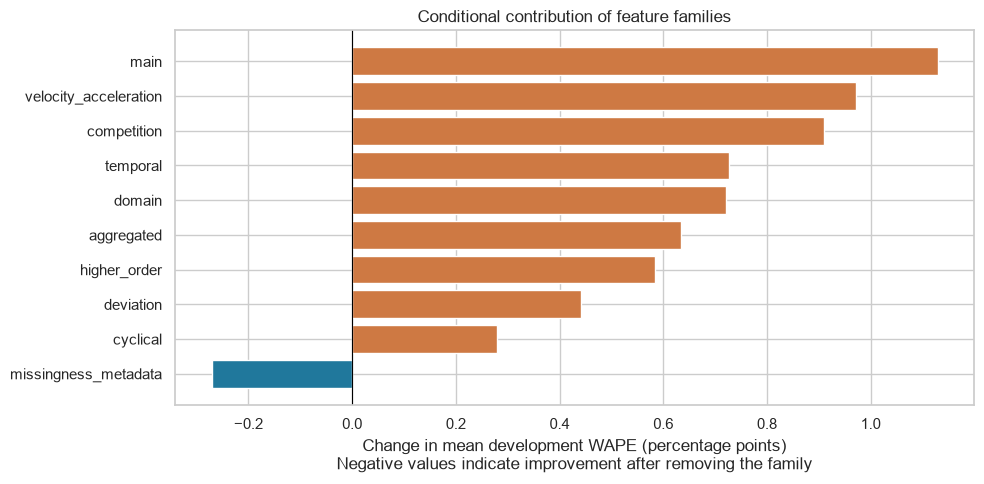

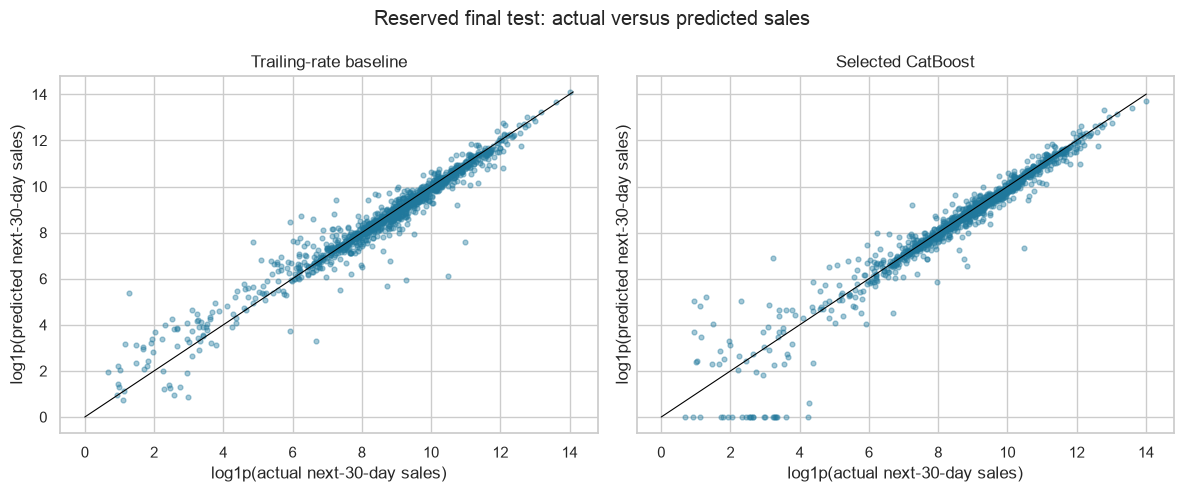

In [25]:
import matplotlib.pyplot as plt
import numpy as np

plot_table = ablation_summary[ablation_summary.candidate.str.startswith("drop_")].sort_values("wape_change_vs_full_pp")
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(plot_table.candidate.str.removeprefix("drop_"), plot_table.wape_change_vs_full_pp,
        color=np.where(plot_table.wape_change_vs_full_pp.lt(0), "#20789c", "#ce7943"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Change in mean development WAPE (percentage points)\nNegative values indicate improvement after removing the family")
ax.set_title("Conditional contribution of feature families")
fig.tight_layout()
fig.savefig(MODEL_OUTPUT_DIR / "feature_family_ablation.png", dpi=160)
plt.show()

final_predictions = pd.read_parquet(MODEL_OUTPUT_DIR / "final_predictions.parquet")
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, column, title in zip(axes, ["baseline_prediction", "main_prediction"], ["Trailing-rate baseline", "Selected CatBoost"]):
    actual = np.log1p(final_predictions.actual)
    predicted = np.log1p(final_predictions[column])
    ax.scatter(actual, predicted, s=12, alpha=0.4, color="#20789c")
    maximum = max(actual.max(), predicted.max())
    ax.plot([0, maximum], [0, maximum], color="black", linewidth=0.8)
    ax.set(title=title, xlabel="log1p(actual next-30-day sales)", ylabel="log1p(predicted next-30-day sales)")
fig.suptitle("Reserved final test: actual versus predicted sales")
fig.tight_layout()
fig.savefig(MODEL_OUTPUT_DIR / "final_actual_vs_predicted.png", dpi=160)
plt.show()

### Interpretation of this run

The discussion below is generated from the saved experiment results and includes improvements, regressions and limits.


In [26]:
import json
from IPython.display import Markdown, display

run = json.loads((MODEL_OUTPUT_DIR / "results.json").read_text())
final_scores = pd.read_csv(MODEL_OUTPUT_DIR / "final_metrics.csv").set_index("candidate")
baseline_score = final_scores.loc["baseline"]
selected_name = run["selection"]["candidate"]
main_score = final_scores.loc[selected_name]
ablation = pd.read_csv(MODEL_OUTPUT_DIR / "ablation_summary.csv").set_index("candidate")
segments = pd.read_csv(MODEL_OUTPUT_DIR / "segment_metrics.csv")
sparse = segments[segments.role.eq("final_test") & segments.segment.eq("sparse")].set_index("candidate")
absolute_error_reduction = 100 * (1 - main_score.wape_pct / baseline_score.wape_pct)

interpretation = f"""
**Chosen configuration.** Development selected raw-scale MAE CatBoost with the explicit
missingness/metadata family removed: **{run['selected_feature_count']} declared inputs**,
**{run['fitted_feature_count']} fitted inputs** after training-only constant removal.
All **{run['feature_count']} extracted features** remain available for inspection and later experiments.

**Development result.** Equal-fold WAPE was **{run['main_mean_development_wape_pct']:.2f}%**
for the selected model versus **{run['baseline_mean_development_wape_pct']:.2f}%** for the baseline.
It wins in two development horizons; the June 25–July 24 horizon still favors the baseline.
The reporting anomaly and incomplete-label coverage in that horizon remain part of the interpretation.

**Final result on {int(main_score['n']):,} products.** WAPE decreased from
**{baseline_score.wape_pct:.2f}% to {main_score.wape_pct:.2f}%**, a
**{absolute_error_reduction:.1f}% reduction in aggregate absolute error**.
MAE decreased from **{baseline_score.mae:,.2f} to {main_score.mae:,.2f}** recorded units.
Overall sMAPE decreased from **{baseline_score.smape_pct:.2f}% to {main_score.smape_pct:.2f}%**.
These are held-out results after selection; no changes were made in response to them.

**Tradeoffs.** RMSE increased from **{baseline_score.rmse:,.2f} to {main_score.rmse:,.2f}**,
and bias changed from **{baseline_score.bias_pct:.2f}% to {main_score.bias_pct:.2f}%**.
The selected MAE model therefore improves absolute error while missing some large outcomes more severely
and underforecasting total volume more. It is not uniformly superior under every business objective.

**Feature-family evidence.** Against the full-feature MAE model, dropping competition
increased mean development WAPE by **{ablation.loc['drop_competition', 'wape_change_vs_full_pp']:.2f} percentage points**
and worsened all three folds. Dropping the explicit metadata columns reduced mean WAPE by
**{-ablation.loc['drop_missingness_metadata', 'wape_change_vs_full_pp']:.2f} percentage points**
and improved all three folds. This is conditional evidence: observed-day counts and implicit NaN handling
still carry related information. The preprocessing and completeness controls were retained.

**Sparse products need further work.** On the {int(sparse.loc[selected_name, 'n'])} sparse products,
WAPE improved from **{sparse.loc['baseline', 'wape_pct']:.2f}% to {sparse.loc[selected_name, 'wape_pct']:.2f}%**,
but sMAPE worsened from **{sparse.loc['baseline', 'smape_pct']:.2f}% to {sparse.loc[selected_name, 'smape_pct']:.2f}%**.
The volume-weighted improvement does not establish better relative accuracy for very small outcomes.

**Sampling limitation.** Weekly training origins mostly share a weekday. In the final fit,
`horizon_weekday_0_count` was constant in training and removed, even though the final horizon has a different
calendar composition. A later experiment should compare rotating or daily training origins on development data.
The other removed constant was the deliberately unknown verified-holiday count.

**Scope of evidence.** This is one fixed-budget, seed-42 experiment with three development horizons
and one reserved test, not a significance test or a production refit. The final test excludes products
whose outcomes or historical coverage fail the declared rules. The full-dataset EDA also predates the
holdout designation. Further tuning requires an explicitly separated validation design.
"""
display(Markdown(interpretation))

residuals = pd.read_parquet(MODEL_OUTPUT_DIR / "final_predictions.parquet")
residuals["main_absolute_error"] = (residuals.main_prediction - residuals.actual).abs()
residuals["baseline_absolute_error"] = (residuals.baseline_prediction - residuals.actual).abs()
residuals["extra_squared_error"] = (
    (residuals.main_prediction - residuals.actual) ** 2
    - (residuals.baseline_prediction - residuals.actual) ** 2
)
print("Largest contributors to the main model's RMSE regression (diagnosis only):")
display(residuals.nlargest(5, "extra_squared_error")[[
    "product_id", "actual", "baseline_prediction", "main_prediction",
    "baseline_absolute_error", "main_absolute_error"
]])


**Chosen configuration.** Development selected raw-scale MAE CatBoost with the explicit
missingness/metadata family removed: **172 declared inputs**,
**170 fitted inputs** after training-only constant removal.
All **215 extracted features** remain available for inspection and later experiments.

**Development result.** Equal-fold WAPE was **19.25%**
for the selected model versus **20.60%** for the baseline.
It wins in two development horizons; the June 25–July 24 horizon still favors the baseline.
The reporting anomaly and incomplete-label coverage in that horizon remain part of the interpretation.

**Final result on 1,232 products.** WAPE decreased from
**19.21% to 17.73%**, a
**7.7% reduction in aggregate absolute error**.
MAE decreased from **4,778.66 to 4,410.88** recorded units.
Overall sMAPE decreased from **27.28% to 25.55%**.
These are held-out results after selection; no changes were made in response to them.

**Tradeoffs.** RMSE increased from **14,165.58 to 17,025.70**,
and bias changed from **-5.30% to -6.24%**.
The selected MAE model therefore improves absolute error while missing some large outcomes more severely
and underforecasting total volume more. It is not uniformly superior under every business objective.

**Feature-family evidence.** Against the full-feature MAE model, dropping competition
increased mean development WAPE by **0.91 percentage points**
and worsened all three folds. Dropping the explicit metadata columns reduced mean WAPE by
**0.27 percentage points**
and improved all three folds. This is conditional evidence: observed-day counts and implicit NaN handling
still carry related information. The preprocessing and completeness controls were retained.

**Sparse products need further work.** On the 60 sparse products,
WAPE improved from **54.09% to 36.77%**,
but sMAPE worsened from **79.90% to 118.75%**.
The volume-weighted improvement does not establish better relative accuracy for very small outcomes.

**Sampling limitation.** Weekly training origins mostly share a weekday. In the final fit,
`horizon_weekday_0_count` was constant in training and removed, even though the final horizon has a different
calendar composition. A later experiment should compare rotating or daily training origins on development data.
The other removed constant was the deliberately unknown verified-holiday count.

**Scope of evidence.** This is one fixed-budget, seed-42 experiment with three development horizons
and one reserved test, not a significance test or a production refit. The final test excludes products
whose outcomes or historical coverage fail the declared rules. The full-dataset EDA also predates the
holdout designation. Further tuning requires an explicitly separated validation design.


Largest contributors to the main model's RMSE regression (diagnosis only):


,product_id,actual,baseline_prediction,main_prediction,baseline_absolute_error,main_absolute_error
401,P_0402,1215762.65,1335734.30,891316.557408,119971.65,324446.092592
118,P_0119,354991.41,443083.81,613904.006795,88092.40,258912.596795
175,P_0176,801952.86,845393.36,658709.026075,43440.50,143243.833925
69,P_0070,447889.21,378103.77,347013.807522,69785.44,100875.402478
61,P_0062,419490.89,424063.47,451641.022508,4572.58,32150.132508


## 15. Development-only XGBoost comparison and refinement

The earlier final-test results remain fixed. This implementation has no final-test evaluation branch: a Parquet date predicate supplies observations only through **August 23, 2026**, the end of the last development target. The protected August 24–September 22 outcomes never enter preprocessing or training. Hashes of the original modeling artifacts are checked before and after the experiment.

| Candidate group | Configurations | Purpose |
|---|---:|---|
| Weekly CatBoost control | 1 | Reproduce the previous MAE model without the metadata columns |
| Rotating CatBoost | 6 | Raw RMSE, raw MAE and log1p RMSE × full 215 / reduced 172 features |
| Rotating XGBoost | 6 | Same objectives and feature sets, using CPU histogram trees |
| Baseline | 1 | The same trailing-30-day rate forecast |
| Sequential refinement policy | 1 | Choose a model, blend weight and sparse-product route using earlier completed outcomes |

**Matched model settings:** 300 trees, depth 6, learning rate 0.07, L2 5, seed 42, eight CPU threads. No early stopping uses the reported development labels. CatBoost uses native one-hot splits; XGBoost uses native categorical splits and a training-only category vocabulary. Unknown prediction categories become missing. All comparisons at an origin use identical evaluation products and complete labels.

**Training cutoffs:** compare the old seven-day grid with a five-day grid that rotates across weekdays. Both include the same development origins as additional potential training samples once their outcomes are available. Extra calibration-only origins do not join training unless naturally on a cadence grid. Five-day sampling also increases sample count, so this compares sampling schedules rather than isolating weekday coverage independently of data volume.

**Earlier calibration:** predict the three horizons starting February 24, March 26 and April 25, 2026. Before each reported May 25 / June 24 / July 24 origin, use only predictions whose full outcomes are already available. Earlier development outcomes may join calibration after their horizons close. The current evaluation outcomes are not supplied to policy selection.

**Sparse-product refinement:** identify products using a historical 90-day zero-sales rate of at least 20%. Choose their model or baseline using calibration sMAPE, subject to sparse WAPE no worse than 105% of baseline.

**Blending refinement:** compare model weights 0.25 / 0.5 / 0.75 / 1, plus baseline, for regular products. Choose overall calibration WAPE subject to overall RMSE and sMAPE at most 105% of baseline. The unmodified baseline remains available. This 5% tolerance is a declared experiment setting, not a business-validated cost limit or a guarantee on later horizons.

Static candidate rankings are development evidence for model selection. The sequential policy provides an additional evaluation whose choices use only earlier completed horizons. Neither is a fresh external test estimate.

In [27]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np
from IPython.display import display, Markdown

REFINE_ROOT = PROJECT_ROOT
from okala.modeling import OBJECTIVES, ExperimentConfig
from okala.refinement import RefinementConfig, run_refinements

REFINE_OUTPUT = REFINE_ROOT / "data/refinement"
refinement_config = RefinementConfig(model=ExperimentConfig(
    iterations=300, depth=6, learning_rate=0.07, l2_leaf_reg=5.0,
    thread_count=8, random_seed=42,
))
refinement_plan = pd.read_csv(REFINE_ROOT / "data/processed/backtest_plan.csv")
# The pipeline uses three earlier calibration windows and the reported development windows.
refinement_window_count = 3 + int(refinement_plan.role.str.startswith("development_").sum())
# One weekly control plus two algorithms x three objectives x two feature sets.
refinement_candidate_count = 1 + 2 * len(OBJECTIVES) * 2
with tqdm(total=refinement_window_count * refinement_candidate_count,
          desc="Refinement comparison", unit="evaluation") as refinement_bar:
    def refinement_progress(message):
        tqdm.write(message)
        # Feature-building and policy messages are logged without counting them as model evaluations.
        if message.startswith("  WAPE="):
            refinement_bar.update(1)

    refinement_results = run_refinements(
        DATA_PATH, REFINE_ROOT / "data/processed",
        REFINE_OUTPUT, config=refinement_config,
        progress=refinement_progress,
    )
assert refinement_results["final_test_scored"] is False
assert refinement_results["original_artifacts_unchanged"] is True
tqdm.write("Protected final test was not scored. Original modeling artifacts are unchanged.")

Refinement comparison:   0%|          | 0/78 [00:00<?, ?evaluation/s]

  WAPE=23.993%, RMSE=14548.84, sMAPE=33.833%, fit=2.1s
  WAPE=23.264%, RMSE=13647.23, sMAPE=41.058%, fit=2.0s
  WAPE=23.086%, RMSE=13450.05, sMAPE=41.157%, fit=1.6s
  WAPE=24.309%, RMSE=13826.37, sMAPE=33.259%, fit=2.9s
  WAPE=23.297%, RMSE=12735.08, sMAPE=32.820%, fit=2.5s
  WAPE=21.882%, RMSE=11391.76, sMAPE=28.980%, fit=1.9s
  WAPE=20.926%, RMSE=11139.79, sMAPE=28.048%, fit=1.7s
  WAPE=28.193%, RMSE=14862.34, sMAPE=44.481%, fit=4.2s
  WAPE=29.687%, RMSE=15393.15, sMAPE=41.291%, fit=3.1s
  WAPE=27.092%, RMSE=14641.85, sMAPE=42.579%, fit=4.4s
  WAPE=26.929%, RMSE=14624.67, sMAPE=39.513%, fit=2.9s
  WAPE=27.175%, RMSE=17129.59, sMAPE=32.953%, fit=4.0s
  WAPE=27.530%, RMSE=18000.04, sMAPE=33.046%, fit=4.0s
  WAPE=21.223%, RMSE=10062.46, sMAPE=34.923%, fit=2.1s
  WAPE=23.600%, RMSE=10495.23, sMAPE=44.603%, fit=2.0s
  WAPE=22.115%, RMSE=9813.26, sMAPE=41.502%, fit=1.7s
  WAPE=22.180%, RMSE=11043.52, sMAPE=35.125%, fit=2.9s
  WAPE=21.709%, RMSE=10631.34, sMAPE=35.077%, fit=2.6s
  WAPE=23.4

### Algorithm, objective and sampling comparisons

The leaderboard uses an equal-weight mean over the same three development horizons. The full and reduced feature sets are tested for each algorithm, rather than transferring CatBoost's feature preference to XGBoost without checking it. Training-only constant removal may reduce fitted column counts.

The cadence comparison holds algorithm, loss and feature set fixed. `weekly_control_parity.csv` verifies agreement with the original development results. Actual fit times and training row counts are saved separately, because a fixed tree budget does not imply equal wall-clock cost.

In [28]:
refinement_leaderboard = pd.read_csv(REFINE_OUTPUT / "leaderboard.csv")
refinement_metrics = pd.read_csv(REFINE_OUTPUT / "development_metrics.csv")
refinement_fit_audit = pd.read_csv(REFINE_OUTPUT / "fit_audit.csv")
print("All base candidates, baseline and sequential policy:")
display(refinement_leaderboard)
print("Matched loss/feature-set comparison of sampling schedules:")
cadence_candidates = ["weekly_catboost_raw_mae_no_metadata", "rotating_catboost_raw_mae_no_metadata"]
display(refinement_metrics[refinement_metrics.candidate.isin(cadence_candidates)][
    ["role", "candidate", "n", "wape_pct", "rmse", "smape_pct", "bias_pct"]
])
print("Original weekly-control parity (zero difference means exact agreement):")
display(pd.read_csv(REFINE_OUTPUT / "weekly_control_parity.csv"))
print("Training size and measured fit time:")
display(refinement_fit_audit.groupby(["cadence", "algorithm", "objective", "feature_set"])[
    ["train_samples", "declared_features", "used_features", "fit_seconds"]
].mean().reset_index())

All base candidates, baseline and sequential policy:


,candidate,wape_pct,mae,rmse,smape_pct,bias_pct
0,weekly_catboost_raw_mae_no_metadata,19.249627,4851.493037,14646.960509,26.328498,-7.053822
1,refined_policy,19.483604,4903.651355,15026.405170,26.433704,-5.988250
2,rotating_catboost_raw_mae_no_metadata,20.158951,5088.099017,14843.183303,28.250331,-5.617421
3,rotating_catboost_raw_mae_full,20.220475,5101.936680,14514.117797,29.029640,-5.604400
4,rotating_xgboost_raw_mae_no_metadata,20.374722,5125.183678,17200.280721,29.090420,-6.697162
5,baseline,20.597916,5130.728795,13254.551108,28.410463,-0.921764
6,rotating_catboost_raw_rmse_no_metadata,21.109415,5336.712201,14385.634652,36.453436,-4.432844
7,rotating_xgboost_log_rmse_no_metadata,21.173723,5350.780151,16669.399045,27.351339,-8.351210
8,rotating_xgboost_raw_mae_full,21.208525,5329.051827,18007.343667,32.768909,-5.009699
9,rotating_catboost_raw_rmse_full,21.261690,5346.617586,14216.482618,38.433172,-2.609662


Matched loss/feature-set comparison of sampling schedules:


,role,candidate,n,wape_pct,rmse,smape_pct,bias_pct
1,development_1,weekly_catboost_raw_mae_no_metadata,1233,19.535552,11680.391652,31.932706,-4.008667
5,development_1,rotating_catboost_raw_mae_no_metadata,1233,20.243284,12824.875691,32.850441,-0.805083
16,development_2,weekly_catboost_raw_mae_no_metadata,968,21.963634,17441.405947,26.114881,-14.337718
20,development_2,rotating_catboost_raw_mae_no_metadata,968,23.396403,16316.002156,30.983910,-16.672326
31,development_3,weekly_catboost_raw_mae_no_metadata,1191,16.249694,14819.083927,20.937908,-2.815081
35,development_3,rotating_catboost_raw_mae_no_metadata,1191,16.837166,15388.672061,20.916642,0.625146


Original weekly-control parity (zero difference means exact agreement):


,role,wape_pct_original,wape_pct_control,difference_pp
0,development_1,19.535552,19.535552,0.0
1,development_2,21.963634,21.963634,0.0
2,development_3,16.249694,16.249694,0.0


Training size and measured fit time:


,cadence,algorithm,objective,feature_set,train_samples,declared_features,used_features,fit_seconds
0,rotating,catboost,log_rmse,full,117800.166667,215.0,213.000000,2.249313
1,rotating,catboost,log_rmse,no_metadata,117800.166667,172.0,171.000000,1.859203
2,rotating,catboost,raw_mae,full,117800.166667,215.0,213.000000,3.260703
3,rotating,catboost,raw_mae,no_metadata,117800.166667,172.0,171.000000,2.855138
4,rotating,catboost,raw_rmse,full,117800.166667,215.0,213.000000,2.226956
5,rotating,catboost,raw_rmse,no_metadata,117800.166667,172.0,171.000000,1.887757
6,rotating,xgboost,log_rmse,full,117800.166667,215.0,213.000000,4.314442
7,rotating,xgboost,log_rmse,no_metadata,117800.166667,172.0,171.000000,3.942131
8,rotating,xgboost,raw_mae,full,117800.166667,215.0,213.000000,4.169959
9,rotating,xgboost,raw_mae,no_metadata,117800.166667,172.0,171.000000,3.381259


### Chronological routing and blend decisions

Each decision below was selected before using that origin's evaluation outcomes. A model weight of zero is a baseline choice for regular products. The sparse route can independently select a different candidate or the baseline.

Calibration guardrails describe earlier performance only. A later window can violate those limits because its distribution differs; such a result is evidence to report, not a reason to rewrite the already-issued decision.

In [29]:
policy_decisions = json.loads((REFINE_OUTPUT / "selected_policies.json").read_text())
policy_table = pd.json_normalize(policy_decisions)
display(policy_table[["forecast_origin", "main", "weight", "sparse", "calibrated_through",
                      "calibration_metrics.wape_pct", "calibration_metrics.rmse", "calibration_metrics.smape_pct"]])
for decision in policy_decisions:
    assert pd.Timestamp(decision["calibrated_through"]) <= pd.Timestamp(decision["forecast_origin"])
print("Sequential policy versus baseline on the reported development windows:")
display(refinement_metrics[refinement_metrics.candidate.isin(["baseline", "refined_policy"])][
    ["role", "candidate", "n", "wape_pct", "mae", "rmse", "smape_pct", "bias_pct"]
])
refinement_segments = pd.read_csv(REFINE_OUTPUT / "segment_metrics.csv")
print("Sparse-product results by window:")
display(refinement_segments[
    refinement_segments.segment.eq("sparse") & refinement_segments.candidate.isin(["baseline", "refined_policy"])
][["role", "candidate", "n", "wape_pct", "rmse", "smape_pct"]])

,forecast_origin,main,weight,sparse,calibrated_through,calibration_metrics.wape_pct,calibration_metrics.rmse,calibration_metrics.smape_pct
0,2026-05-25,rotating_catboost_raw_mae_no_metadata,1.0,rotating_catboost_log_rmse_full,2026-05-25,22.495544,12726.768595,33.039076
1,2026-06-24,weekly_catboost_raw_mae_no_metadata,1.0,rotating_catboost_log_rmse_full,2026-06-24,21.807935,12700.201220,33.064517
2,2026-07-24,weekly_catboost_raw_mae_no_metadata,1.0,rotating_catboost_log_rmse_full,2026-07-24,21.843933,13649.921156,31.708914


Sequential policy versus baseline on the reported development windows:


,role,candidate,n,wape_pct,mae,rmse,smape_pct,bias_pct
0,development_1,baseline,1233,23.430095,5148.570584,12368.717042,36.691601,3.433259
14,development_1,refined_policy,1233,20.188135,4436.176585,12809.124024,32.492859,-0.742304
15,development_2,baseline,968,20.703375,5941.775537,14257.989451,25.149903,-3.908744
29,development_2,refined_policy,968,21.987924,6310.435212,17448.800902,26.286500,-14.369439
30,development_3,baseline,1191,17.660278,4301.840263,13136.946831,23.389886,-2.289805
44,development_3,refined_policy,1191,16.274753,3964.342269,14821.290583,20.521753,-2.853008


Sparse-product results by window:


,role,candidate,n,wape_pct,rmse,smape_pct
45,development_1,baseline,59,52.265280,3864.009289,93.579811
59,development_1,refined_policy,59,40.710557,3090.184548,95.003197
120,development_2,baseline,12,33.750169,10034.418445,52.754167
134,development_2,refined_policy,12,31.538318,9254.221561,43.618958
195,development_3,baseline,27,63.515586,6515.689070,63.793663
209,development_3,refined_policy,27,46.354989,3962.114524,55.444511


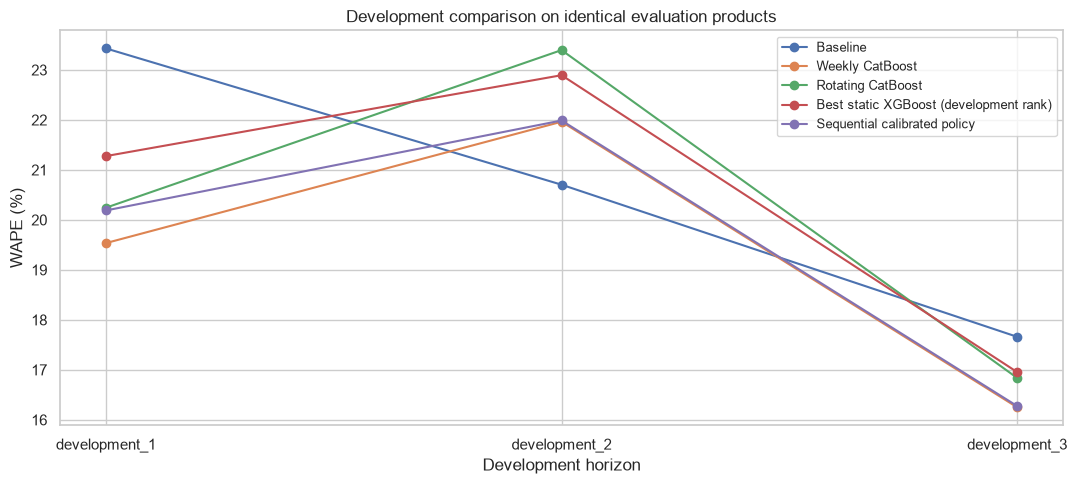

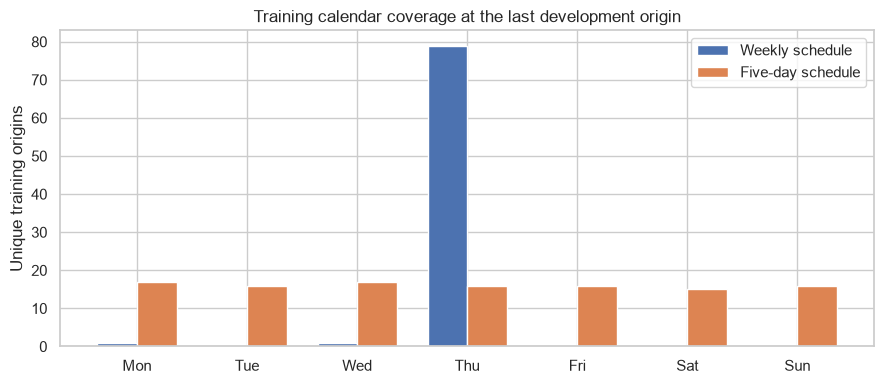

In [30]:
import matplotlib.pyplot as plt

best_xgb_name = refinement_leaderboard[
    refinement_leaderboard.candidate.str.startswith("rotating_xgboost_")
].iloc[0].candidate
plot_candidates = {
    "baseline": "Baseline",
    "weekly_catboost_raw_mae_no_metadata": "Weekly CatBoost",
    "rotating_catboost_raw_mae_no_metadata": "Rotating CatBoost",
    best_xgb_name: "Best static XGBoost (development rank)",
    "refined_policy": "Sequential calibrated policy",
}
fig, ax = plt.subplots(figsize=(11, 5))
for candidate, title in plot_candidates.items():
    part = refinement_metrics[refinement_metrics.candidate.eq(candidate)].sort_values("role")
    ax.plot(part.role, part.wape_pct, marker="o", label=title)
ax.set(ylabel="WAPE (%)", xlabel="Development horizon", title="Development comparison on identical evaluation products")
ax.legend(fontsize=9)
fig.tight_layout(); fig.savefig(REFINE_OUTPUT / "development_comparison.png", dpi=160)
plt.show()

weekdays = pd.read_csv(REFINE_OUTPUT / "training_weekdays.csv")
last_role = sorted(weekdays.role.unique())[-1]
fig, ax = plt.subplots(figsize=(9, 4))
positions = np.arange(7)
for offset, candidate, label in [(-.18, cadence_candidates[0], "Weekly schedule"), (.18, cadence_candidates[1], "Five-day schedule")]:
    part = weekdays[weekdays.role.eq(last_role) & weekdays.candidate.eq(candidate)].sort_values("weekday")
    ax.bar(positions + offset, part.training_origins, width=.36, label=label)
ax.set_xticks(positions, ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set(ylabel="Unique training origins", title="Training calendar coverage at the last development origin")
ax.legend(); fig.tight_layout(); fig.savefig(REFINE_OUTPUT / "training_calendar_coverage.png", dpi=160)
plt.show()

### Source isolation and reproducibility

The refinement runner has no option to score the protected final test. New source rows are date-filtered by Parquet before conversion to the working panel. It records the exact source/implementation hashes, library versions, fixed settings, prediction cutoffs, calibration decisions and fit metadata.

Only development models are saved for the last development origin. No production refit or new final-test claim is implied. Original final metrics, predictions, selected model, plots and all other modeling artifacts remain byte-for-byte unchanged.

In [31]:
preservation = json.loads((REFINE_OUTPUT / "holdout_preservation.json").read_text())
assert preservation["original_artifacts_unchanged"] and not preservation["final_test_scored"]
print("Source read through:", preservation["source_read_through"])
print("Original modeling files preserved:", len(preservation["protected_files"]))
print("Base fits:", len(refinement_fit_audit))
print("Feature rows:", refinement_results["protocol"]["feature_rows"])
print("New final-test scores:", refinement_results["final_test_scored"])
print("Refinement outputs:")
for file in sorted(REFINE_OUTPUT.iterdir()):
    if file.is_file(): print(" ", file.name)

Source read through: 2026-08-23
Original modeling files preserved: 99
Base fits: 78
Feature rows: 233415
New final-test scores: False
Refinement outputs:
  all_window_metrics.csv
  development_comparison.png
  development_metrics.csv
  feature_catalog.csv
  fit_audit.csv
  holdout_preservation.json
  leaderboard.csv
  policy_calibration_scores.csv
  predictions.parquet
  protocol.json
  results.json
  segment_metrics.csv
  selected_policies.json
  sparse_route_calibration_scores.csv
  training_calendar_coverage.png
  training_weekdays.csv
  weekly_control_parity.csv


### Interpretation and retained model choice


In [32]:
leader = refinement_leaderboard.set_index("candidate")
weekly_name = "weekly_catboost_raw_mae_no_metadata"
rotating_name = "rotating_catboost_raw_mae_no_metadata"
xgb_name = refinement_leaderboard[refinement_leaderboard.candidate.str.startswith("rotating_xgboost_")].iloc[0].candidate
sparse_means = refinement_segments[refinement_segments.segment.eq("sparse")].groupby("candidate")[["wape_pct", "rmse", "smape_pct"]].mean()
chosen_weights = [decision["weight"] for decision in policy_decisions]

summary = f"""
**XGBoost was tested.** Six rotating XGBoost configurations covered both feature sets and
three objectives. Its best development candidate was `{xgb_name}`, with mean WAPE
**{leader.loc[xgb_name, 'wape_pct']:.2f}%**. The prior weekly CatBoost control achieved
**{leader.loc[weekly_name, 'wape_pct']:.2f}%** and remains preferable under this metric and budget.
This does not establish that a separately tuned XGBoost model could never improve.

**Rotating sampling did not improve this experiment.** Holding loss, algorithm and feature
set fixed, the five-day CatBoost schedule gave **{leader.loc[rotating_name, 'wape_pct']:.2f}%**
versus **{leader.loc[weekly_name, 'wape_pct']:.2f}%** for weekly sampling, and was worse in all three
reported windows. The weekly control exactly reproduces the old scores. Rotating origins
fix weekday representation, but that representation change and the larger training set did not
produce a WAPE improvement under the fixed model settings.

**Blending was evaluated, but not selected.** The earlier-outcome calibration grid compared
baseline blends at each origin. Selected model weights were **{chosen_weights}**;
therefore this run provides no evidence that a nontrivial blend should replace the main forecast.
Choices were persisted before evaluating their corresponding reported horizons.

**Sparse routing has a limited benefit.** The sequential policy routed sparse products to the
rotating full-feature log-scale CatBoost model at each origin. Its sparse-product mean sMAPE
was **{sparse_means.loc['refined_policy', 'smape_pct']:.2f}%**, versus
**{sparse_means.loc[weekly_name, 'smape_pct']:.2f}%** for the original weekly model and
**{sparse_means.loc['baseline', 'smape_pct']:.2f}%** for the baseline. Sparse WAPE changed from
**{sparse_means.loc[weekly_name, 'wape_pct']:.2f}% to {sparse_means.loc['refined_policy', 'wape_pct']:.2f}%**.
The improvement is an average across windows; the June development window became worse for this segment.

**The complete refinement did not beat the existing main model.** Its mean WAPE was
**{leader.loc['refined_policy', 'wape_pct']:.2f}%**, versus **{leader.loc[weekly_name, 'wape_pct']:.2f}%**,
and its RMSE was **{leader.loc['refined_policy', 'rmse']:,.2f}**, versus
**{leader.loc[weekly_name, 'rmse']:,.2f}**. It reduced underforecast bias from
**{leader.loc[weekly_name, 'bias_pct']:.2f}% to {leader.loc['refined_policy', 'bias_pct']:.2f}%**.
Calibration guardrails did not guarantee the same bounds on later outcomes; their role and limitations
are visible in the per-window scores. They are not deployment guarantees.

**Decision.** Keep the prior weekly CatBoost/MAE model as the current WAPE-oriented reference.
Retain the XGBoost, calendar and routing experiments as evidence, rather than replacing the reference
because the alternatives are more elaborate. Sparse routing is worth further validation if relative
accuracy on small products becomes a business priority.

**Evaluation scope.** These are development results only. The original final-test report is unchanged,
no new final test was scored, and no new external generalization estimate is claimed. Further choices
must remain within a declared development design and require fresh confirmation before stronger claims.
"""
display(Markdown(summary))


**XGBoost was tested.** Six rotating XGBoost configurations covered both feature sets and
three objectives. Its best development candidate was `rotating_xgboost_raw_mae_no_metadata`, with mean WAPE
**20.37%**. The prior weekly CatBoost control achieved
**19.25%** and remains preferable under this metric and budget.
This does not establish that a separately tuned XGBoost model could never improve.

**Rotating sampling did not improve this experiment.** Holding loss, algorithm and feature
set fixed, the five-day CatBoost schedule gave **20.16%**
versus **19.25%** for weekly sampling, and was worse in all three
reported windows. The weekly control exactly reproduces the old scores. Rotating origins
fix weekday representation, but that representation change and the larger training set did not
produce a WAPE improvement under the fixed model settings.

**Blending was evaluated, but not selected.** The earlier-outcome calibration grid compared
baseline blends at each origin. Selected model weights were **[1.0, 1.0, 1.0]**;
therefore this run provides no evidence that a nontrivial blend should replace the main forecast.
Choices were persisted before evaluating their corresponding reported horizons.

**Sparse routing has a limited benefit.** The sequential policy routed sparse products to the
rotating full-feature log-scale CatBoost model at each origin. Its sparse-product mean sMAPE
was **64.69%**, versus
**68.06%** for the original weekly model and
**70.04%** for the baseline. Sparse WAPE changed from
**40.53% to 39.53%**.
The improvement is an average across windows; the June development window became worse for this segment.

**The complete refinement did not beat the existing main model.** Its mean WAPE was
**19.48%**, versus **19.25%**,
and its RMSE was **15,026.41**, versus
**14,646.96**. It reduced underforecast bias from
**-7.05% to -5.99%**.
Calibration guardrails did not guarantee the same bounds on later outcomes; their role and limitations
are visible in the per-window scores. They are not deployment guarantees.

**Decision.** Keep the prior weekly CatBoost/MAE model as the current WAPE-oriented reference.
Retain the XGBoost, calendar and routing experiments as evidence, rather than replacing the reference
because the alternatives are more elaborate. Sparse routing is worth further validation if relative
accuracy on small products becomes a business priority.

**Evaluation scope.** These are development results only. The original final-test report is unchanged,
no new final test was scored, and no new external generalization estimate is claimed. Further choices
must remain within a declared development design and require fresh confirmation before stronger claims.


## 16. Statistical diagnostics and what the models learned

This section analyzes saved predictions and saved model files. It does **not** retrain, change the selected model, optimize alert thresholds, or produce a new XGBoost final-test result. The final CatBoost report is analyzed retrospectively because that report has already been inspected. All upstream modeling and refinement files are checked for unchanged hashes.

The analysis has two distinct layers:

1. **Regression:** paired errors, bias, tail concentration, standardized differences, distribution distances, category-cluster uncertainty and changes in input distributions.
2. **Explanations and illustrative alerts:** native SHAP, local error cases and explicitly defined high-demand/growth/decline events. A sales forecast has no intrinsic TP/FP/TN/FN classes. Those labels exist only after an event definition is supplied.

**SMD conventions.** Marginal signed SMD is `(mean A - mean B) / sqrt((sample variance A + sample variance B)/2)`. For predicted versus actual sales, A is predicted and B is actual; positive values indicate higher predicted levels. For error profiles, signs are **FP minus TN** and **FN minus TP**. Paired standardized differences use the standard deviation of the paired differences and are labeled `dz`, separately. Identical constants have SMD zero; different constants have undefined SMD with a shift flag. This avoids interpreting floating-point roundoff in calendar constants as a large effect.

**KS conventions.** `ks_d` is the maximum empirical CDF distance, not an iid significance claim. Actual/predicted values are paired, categories may share shocks, and products recur across development horizons. Independent-samples KS p-values are therefore not reported. Alert `score_ks_d` compares scores among actual event/non-event products; it is a ranking-separation diagnostic, different from actual-versus-forecast distribution KS.

**Uncertainty.** Paired bootstrap intervals resample entire Level4 categories (2,000 draws); paired sign flips also operate on categories (5,000 draws). Comparisons within a horizon receive Holm adjustment. These procedures condition on the observed horizon and assumptions about category blocks. Common shocks across categories, temporal generalization and model-training uncertainty are not resolved. Horizons are not pooled as if repeated product rows were independent.

In [33]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

ANALYSIS_ROOT = PROJECT_ROOT
from okala.diagnostics import DiagnosticConfig, run_diagnostics

ANALYSIS_DIR = ANALYSIS_ROOT / "data/analysis"
REFERENCE_MODEL = "weekly_catboost_raw_mae_no_metadata"
analysis_plan = pd.read_csv(ANALYSIS_ROOT / "data/processed/backtest_plan.csv")
# One diagnostic stage per horizon, then three saved-model SHAP explanations.
analysis_stage_count = len(analysis_plan) + 3
with tqdm(total=analysis_stage_count, desc="Statistical analysis", unit="stage") as analysis_bar:
    def analysis_progress(message):
        tqdm.write(message)
        if message.startswith(("Diagnostics:", "Native SHAP:")):
            # The next stage's start confirms that the preceding stage has finished.
            if analysis_bar.postfix:
                analysis_bar.update(1)
            analysis_bar.set_postfix_str(message, refresh=True)

    analysis_results = run_diagnostics(
        ANALYSIS_ROOT / "data/processed", ANALYSIS_ROOT / "data/modeling",
        ANALYSIS_ROOT / "data/refinement", ANALYSIS_DIR,
        config=DiagnosticConfig(bootstrap_repetitions=2000, permutation_repetitions=5000, seed=42),
        progress=analysis_progress,
    )
    analysis_bar.update(1)
assert analysis_results["upstream_artifacts_unchanged"]
regression_stats = pd.read_csv(ANALYSIS_DIR / "regression_statistics.csv")
paired_stats = pd.read_csv(ANALYSIS_DIR / "paired_cluster_inference.csv")
alert_stats = pd.read_csv(ANALYSIS_DIR / "alert_statistics.csv")
profile_stats = pd.read_csv(ANALYSIS_DIR / "error_feature_profiles.csv")
error_rows = pd.read_parquet(ANALYSIS_DIR / "prediction_errors.parquet")
final_stats = regression_stats[regression_stats.role.eq("final_test")].set_index("model")
final_errors = error_rows[error_rows.role.eq("final_test") & error_rows.model.eq(REFERENCE_MODEL)].copy()
tqdm.write("Statistical diagnostics generated from saved outputs; no model fitting occurred.")

Statistical analysis:   0%|          | 0/7 [00:00<?, ?stage/s]

Diagnostics: development_1, 2026-05-25, products=1233, models=15
Diagnostics: development_2, 2026-06-24, products=968, models=15
Diagnostics: development_3, 2026-07-24, products=1191, models=15
Diagnostics: final_test, 2026-08-23, products=1232, models=2
Native SHAP: catboost, development_3, products=1191
Native SHAP: xgboost, development_3, products=1191
Native SHAP: catboost, final_test, products=1232
Analysis complete: 47 regression comparisons, 329 alert comparisons, three native SHAP explanations; upstream artifacts unchanged.
Statistical diagnostics generated from saved outputs; no model fitting occurred.


### Paired error analysis, distribution shape and uncertainty

Residuals are `predicted - actual`, so negative residuals indicate underforecasting. A small marginal SMD or KS distance can coexist with large product-level errors because the assortment has a wide range of sales scales. Likewise, a high cross-product rank correlation can reflect stable SKU popularity without accurately anticipating each product's next change.

A positive paired WAPE gain means `baseline WAPE - model WAPE`. A category-bootstrap interval spanning zero does not resolve an improvement under this procedure; it does not prove equivalence. Interpret the effect size, uncertainty, category assumptions and individual horizons together.

In [34]:
display(final_stats[["n", "wape_pct", "mae", "rmse", "smape_pct", "bias_pct",
                     "median_absolute_error", "p95_absolute_error", "predicted_actual_smd",
                     "residual_dz", "ks_d", "spearman", "residual_skewness",
                     "residual_excess_kurtosis", "zero_prediction_positive_actual",
                     "top_1pct_absolute_error_share", "top_1pct_squared_error_share"]])
display(paired_stats[paired_stats.role.eq("final_test")][[
    "model", "clusters", "paired_wape_gain_pp", "wape_gain_ci_low", "wape_gain_ci_high",
    "paired_mae_gain", "mae_gain_ci_low", "mae_gain_ci_high", "paired_gain_dz",
    "product_win_fraction", "cluster_signflip_p", "cluster_signflip_p_holm"
]])
print("Largest product-level error regressions against the baseline:")
display(final_errors.nlargest(10, "extra_squared_error")[[
    "product_id", "Level4", "actual", "baseline", "predicted", "absolute_error",
    "absolute_error_gain", "extra_squared_error"
]])
category_errors = pd.read_csv(ANALYSIS_DIR / "category_errors.csv")
category_errors = category_errors[category_errors.role.eq("final_test") & category_errors.model.eq(REFERENCE_MODEL)]
category_errors["absolute_error_gain"] = category_errors.baseline_absolute_error - category_errors.model_absolute_error
print("Categories with the largest absolute errors:")
display(category_errors.nlargest(10, "model_absolute_error")[[
    "Level4", "n", "actual_volume", "wape_pct", "bias_pct", "absolute_error_gain"
]])

,n,wape_pct,mae,rmse,smape_pct,bias_pct,median_absolute_error,p95_absolute_error,predicted_actual_smd,residual_dz,ks_d,spearman,residual_skewness,residual_excess_kurtosis,zero_prediction_positive_actual,top_1pct_absolute_error_share,top_1pct_squared_error_share
model,,,,,,,,,,,,,,,,,
baseline,1232,19.209881,4778.658455,14165.580856,27.280563,-5.299800,974.715000,19882.610000,-0.021135,-0.093437,0.038149,0.971859,0.236911,55.604842,0,0.225538,0.616702
weekly_catboost_raw_mae_no_metadata,1232,17.731434,4410.879150,17025.699193,25.554780,-6.242793,805.546544,17585.020118,-0.026588,-0.091557,0.029221,0.984451,-4.219903,168.234002,23,0.301912,0.804143


,model,clusters,paired_wape_gain_pp,wape_gain_ci_low,wape_gain_ci_high,paired_mae_gain,mae_gain_ci_low,mae_gain_ci_high,paired_gain_dz,product_win_fraction,cluster_signflip_p,cluster_signflip_p_holm
42,weekly_catboost_raw_mae_no_metadata,88,1.478448,-0.769491,3.742083,367.779304,-191.24215,883.06612,0.039794,0.624188,0.206759,0.206759


Largest product-level error regressions against the baseline:


,product_id,Level4,actual,baseline,predicted,absolute_error,absolute_error_gain,extra_squared_error
52513,P_0402,L4_006,1215762.65,1335734.30,891316.557408,324446.092592,-204474.442592,9.087207e+10
52230,P_0119,L4_004,354991.41,443083.81,613904.006795,258912.596795,-170820.196795,5.927546e+10
52287,P_0176,L4_085,801952.86,845393.36,658709.026075,143243.833925,-99803.333925,1.863172e+10
52181,P_0070,L4_073,447889.21,378103.77,347013.807522,100875.402478,-31089.962478,5.305839e+09
52173,P_0062,L4_075,419490.89,424063.47,451641.022508,32150.132508,-27577.552508,1.012723e+09
52365,P_0254,L4_036,160288.40,116334.35,110309.780632,49978.619368,-6024.569368,5.659039e+08
52174,P_0063,L4_073,189107.67,158599.33,150997.084081,38110.585919,-7602.245919,5.216579e+08
53152,P_1042,L4_020,198526.18,136534.15,133327.654479,65198.525521,-3206.495521,4.078359e+08
52607,P_0496,L4_036,40593.33,23695.67,14729.634943,25863.695057,-8966.035057,3.833998e+08
53224,P_1115,L4_017,39905.66,20278.33,12423.336639,27482.323361,-7854.993361,3.700460e+08


Categories with the largest absolute errors:


,Level4,n,actual_volume,wape_pct,bias_pct,absolute_error_gain
4132,L4_085,11,2331040.24,18.549167,-10.950282,-74670.793601
4053,L4_006,10,1812271.55,21.168710,-15.673770,-209880.497150
4090,L4_043,10,798704.70,43.463125,-15.941615,29730.783967
4083,L4_036,47,1058271.21,26.161853,-14.998654,38493.957313
4051,L4_004,15,457864.29,58.507821,55.735260,-163828.589997
4080,L4_033,37,1613965.67,16.434928,-7.777538,21854.841175
4089,L4_042,9,719829.69,26.895791,-26.895791,45861.721084
4095,L4_048,20,1051651.92,15.669529,-10.755957,76271.515597
4118,L4_071,8,527386.87,31.054641,25.003464,117971.790019
4082,L4_035,49,1418012.50,11.277072,-9.993342,29911.457749


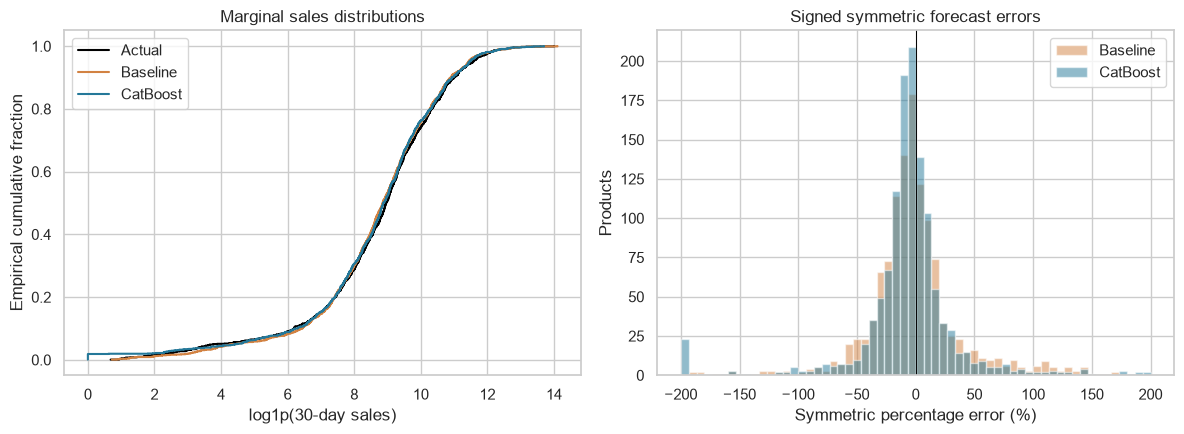

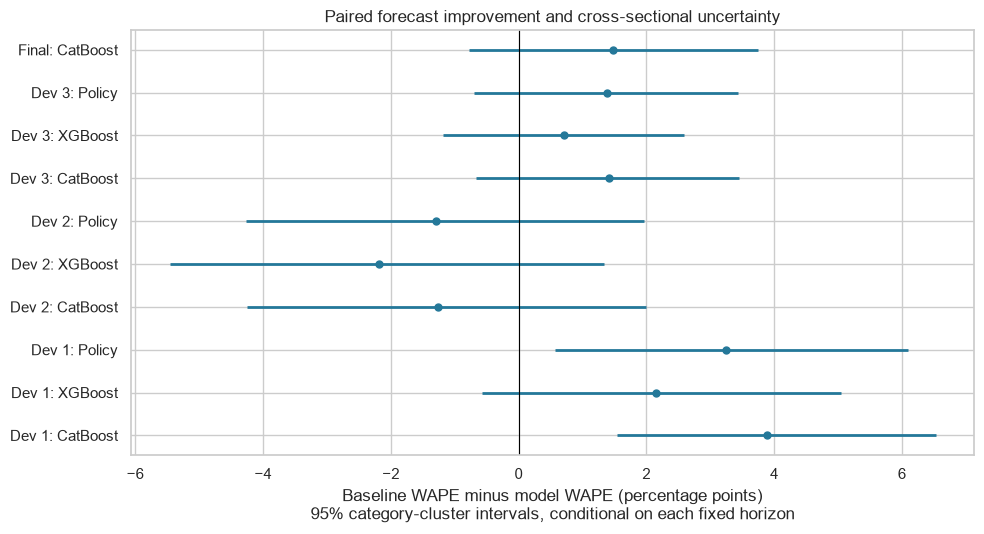

In [35]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, column, color in [("Actual", "actual", "black"), ("Baseline", "baseline", "#d28242"), ("CatBoost", "predicted", "#247899")]:
    x = np.sort(np.log1p(final_errors[column].to_numpy()))
    axes[0].step(x, np.arange(1, len(x) + 1) / len(x), where="post", label=name, color=color)
axes[0].set(title="Marginal sales distributions", xlabel="log1p(30-day sales)", ylabel="Empirical cumulative fraction")
axes[0].legend()
for name, prediction, color in [("Baseline", final_errors.baseline, "#d28242"), ("CatBoost", final_errors.predicted, "#247899")]:
    denominator = np.abs(prediction) + final_errors.actual
    signed_error = np.divide(200 * (prediction - final_errors.actual), denominator,
                             out=np.zeros(len(denominator)), where=denominator.gt(0))
    axes[1].hist(signed_error, bins=np.linspace(-200, 200, 61), alpha=.5, label=name, color=color)
axes[1].axvline(0, color="black", linewidth=.7)
axes[1].set(title="Signed symmetric forecast errors", xlabel="Symmetric percentage error (%)", ylabel="Products")
axes[1].legend(); fig.tight_layout(); fig.savefig(ANALYSIS_DIR / "distribution_and_errors.png", dpi=160)
plt.show()

best_xgb = analysis_results["development_xgboost_reference"]
intervals = paired_stats[
    (paired_stats.role.eq("final_test") & paired_stats.model.eq(REFERENCE_MODEL)) |
    (paired_stats.role.str.startswith("development_") & paired_stats.model.isin([REFERENCE_MODEL, best_xgb, "refined_policy"]))
].copy()
short = {REFERENCE_MODEL: "CatBoost", best_xgb: "XGBoost", "refined_policy": "Policy"}
intervals["label"] = intervals.role.str.replace("development_", "Dev ").str.replace("final_test", "Final") + ": " + intervals.model.map(short)
fig, ax = plt.subplots(figsize=(10, 5.5))
for i, row in enumerate(intervals.itertuples()):
    ax.hlines(i, row.wape_gain_ci_low, row.wape_gain_ci_high, color="#247899", linewidth=2)
    ax.scatter(row.paired_wape_gain_pp, i, color="#247899", s=25)
ax.axvline(0, color="black", linewidth=.8)
ax.set_yticks(range(len(intervals)), intervals.label)
ax.set_xlabel("Baseline WAPE minus model WAPE (percentage points)\n95% category-cluster intervals, conditional on each fixed horizon")
ax.set_title("Paired forecast improvement and cross-sectional uncertainty")
fig.tight_layout(); fig.savefig(ANALYSIS_DIR / "paired_cluster_intervals.png", dpi=160)
plt.show()

### Explicit alert definitions: TN, FP, FN and TP

These are diagnostic alerts derived from regression outputs:

- **High demand:** actual or forecasted 30-day sales at least the 75th percentile of the latest completed historical target for each training-reference product. The source targets all end by the forecast cutoff. q50/q90 are sensitivity scenarios, not threshold optimization.
- **Growth:** actual or forecasted sales at least 1.25 times the known trailing-30-day rate forecast. Factors 1.10 and 1.50 are additional fixed sensitivity scenarios.
- **Decline:** actual or forecasted sales at most 0.75 times that reference. Relative events are undefined for a zero reference and exclude those cases with their count reported.

The same threshold defines actual and forecast events. TN/FP are actual non-events; FN/TP are actual events. The baseline cannot forecast relative growth or decline against itself, so its relative-event predictions are all negative by construction. Its undefined precision is shown as NaN. These are not calibrated event probabilities, stockout labels or learned classifiers.

High-demand discrimination can be strong simply because products have persistent differences in scale. Growth/decline diagnostics ask a harder question about change. ROC AUC/AP/score KS are ranking diagnostics; the operating-point precision/recall depends on the explicit event definition.

,model,event,threshold,n,excluded_undefined_baseline,TN,FP,FN,TP,precision,recall,specificity,npv,fpr,fnr,f1,mcc,roc_auc,average_precision,score_ks_d
316,baseline,high_demand_q75,20919.065,1232,0,894,10,29,299,0.967638,0.911585,0.988938,0.968581,0.011062,0.088415,0.938776,0.918197,0.990220,0.983912,0.939375
319,baseline,growth_25pct,1.250,1232,0,972,0,260,0,NaN,0.000000,1.000000,0.788961,0.000000,1.000000,0.000000,NaN,0.500000,0.211039,0.000000
321,baseline,decline_25pct,0.750,1232,0,1060,0,172,0,NaN,0.000000,1.000000,0.860390,0.000000,1.000000,0.000000,NaN,0.500000,0.139610,0.000000
323,weekly_catboost_raw_mae_no_metadata,high_demand_q75,20919.065,1232,0,899,5,31,297,0.983444,0.905488,0.994469,0.966667,0.005531,0.094512,0.942857,0.924694,0.994547,0.989777,0.955132
326,weekly_catboost_raw_mae_no_metadata,growth_25pct,1.250,1232,0,939,33,192,68,0.673267,0.261538,0.966049,0.830239,0.033951,0.738462,0.376731,0.338514,0.773674,0.522567,0.455571
328,weekly_catboost_raw_mae_no_metadata,decline_25pct,0.750,1232,0,1018,42,91,81,0.658537,0.470930,0.960377,0.917944,0.039623,0.529070,0.549153,0.498639,0.804212,0.512430,0.533875


Fixed threshold sensitivity for the final CatBoost model:


,event,threshold,prevalence,precision,recall,fpr,f1,roc_auc,score_ks_d
322,high_demand_q50,6972.780,0.537338,0.976038,0.922961,0.026316,0.948758,0.991302,0.923687
323,high_demand_q75,20919.065,0.266234,0.983444,0.905488,0.005531,0.942857,0.994547,0.955132
324,high_demand_q90,53719.880,0.111201,0.954198,0.912409,0.005479,0.932836,0.995100,0.941593
325,growth_10pct,1.100,0.391234,0.717949,0.464730,0.117333,0.564232,0.782924,0.467934
326,growth_25pct,1.250,0.211039,0.673267,0.261538,0.033951,0.376731,0.773674,0.455571
327,growth_50pct,1.500,0.096591,0.634146,0.218487,0.013477,0.325000,0.816296,0.609534
328,decline_25pct,0.750,0.139610,0.658537,0.470930,0.039623,0.549153,0.804212,0.533875


Actual SKU identifiers for high-demand false alarms and misses:


,product_id,actual,predicted,decision_score_threshold,outcome
156516,P_0181,47228.30,18275.107123,20919.065,FN
156831,P_0496,40593.33,14729.634943,20919.065,FN
157448,P_1115,39905.66,12423.336639,20919.065,FN
156832,P_0497,35580.09,1539.025697,20919.065,FN
157528,P_1195,31649.20,20331.885288,20919.065,FN
157076,P_0741,27172.09,18686.867069,20919.065,FN
156561,P_0226,26942.77,19747.591480,20919.065,FN
157038,P_0703,26244.11,20587.321329,20919.065,FN
157035,P_0700,26160.51,13420.084504,20919.065,FN
157340,P_1006,25576.50,20128.717550,20919.065,FN


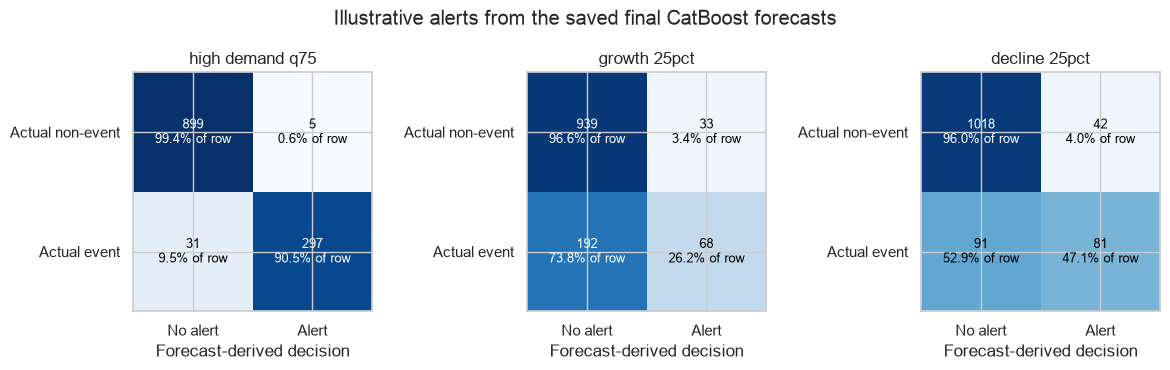

In [36]:
alert_events = ["high_demand_q75", "growth_25pct", "decline_25pct"]
final_alerts = alert_stats[alert_stats.role.eq("final_test") & alert_stats.event.isin(alert_events)]
display(final_alerts[["model", "event", "threshold", "n", "excluded_undefined_baseline",
                      "TN", "FP", "FN", "TP", "precision", "recall", "specificity",
                      "npv", "fpr", "fnr", "f1", "mcc", "roc_auc", "average_precision", "score_ks_d"]])
print("Fixed threshold sensitivity for the final CatBoost model:")
display(alert_stats[alert_stats.role.eq("final_test") & alert_stats.model.eq(REFERENCE_MODEL)][
    ["event", "threshold", "prevalence", "precision", "recall", "fpr", "f1", "roc_auc", "score_ks_d"]
])
alert_cases = pd.read_parquet(ANALYSIS_DIR / "alert_cases.parquet")
print("Actual SKU identifiers for high-demand false alarms and misses:")
display(alert_cases[alert_cases.role.eq("final_test") & alert_cases.model.eq(REFERENCE_MODEL)
                    & alert_cases.event.eq("high_demand_q75") & alert_cases.outcome.isin(["FP", "FN"])][
    ["product_id", "actual", "predicted", "decision_score_threshold", "outcome"]
].sort_values(["outcome", "actual"], ascending=[True, False]).head(36))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.7))
for ax, event in zip(axes, alert_events):
    row = final_alerts[final_alerts.model.eq(REFERENCE_MODEL) & final_alerts.event.eq(event)].iloc[0]
    counts = np.array([[row.TN, row.FP], [row.FN, row.TP]], dtype=int)
    fractions = counts / counts.sum(axis=1, keepdims=True)
    ax.imshow(fractions, vmin=0, vmax=1, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{counts[i,j]}\n{100*fractions[i,j]:.1f}% of row", ha="center", va="center",
                    color="white" if fractions[i,j] > .55 else "black", fontsize=9)
    ax.set_xticks([0, 1], ["No alert", "Alert"])
    ax.set_yticks([0, 1], ["Actual non-event", "Actual event"])
    ax.set(title=event.replace("_", " "), xlabel="Forecast-derived decision")
fig.suptitle("Illustrative alerts from the saved final CatBoost forecasts")
fig.tight_layout(); fig.savefig(ANALYSIS_DIR / "alert_confusion_matrices.png", dpi=160)
plt.show()

### Which inputs distinguish false alarms, misses and error regressions?

`FP_minus_TN` compares features among actual non-events; `FN_minus_TP` compares features among actual events. Positive SMD means higher values in the error group. Profiles include valid-observation counts, missingness differences, KS distances and whether the feature was actually used by the explained model.

These are post-outcome associations. Conditioning on errors or a threshold can itself create differences, especially near the decision boundary. They are not causal mechanisms. High-demand false positives are rare here, so large SMDs based on that small group need particular restraint. No per-feature iid significance claim is made, and correlated feature rows are not independent findings.

Covariate drift separately aligns each evaluated product to its latest eligible historical training snapshot. Deterministic calendar changes and administrative product-age shifts should not be confused with evidence of a novel demand mechanism.

FN_minus_TP (positive SMD means higher feature values in the error group)


,feature,family,n_a,n_b,mean_a,mean_b,smd,ks_d,missing_rate_difference
2383,num_stores_with_stock_mean_30d,aggregated,31,297,263.515795,324.132323,-0.907541,0.417834,0.0
2292,sale_qty_last_observed,main,31,297,664.675484,2707.360606,-0.894773,0.925926,0.0
2407,sales_lag_0d,temporal,31,297,664.675484,2707.360606,-0.894773,0.925926,0.0
2440,sales_iqr_90d,higher_order,31,297,232.062016,884.712407,-0.852568,0.623221,0.0
2308,sales_min_7d,aggregated,31,297,482.489032,2167.698956,-0.832150,0.919192,0.0
2389,stock_usable_mean_30d,aggregated,31,297,18042.313415,47403.909439,-0.813183,0.572716,0.0
2413,sales_lag_60d,temporal,31,297,371.048387,1740.521616,-0.812203,0.739655,0.0
2358,sales_median_90d,aggregated,31,297,498.993548,2374.346347,-0.810518,0.886934,0.0
2441,sales_p90_minus_p10_90d,higher_order,31,297,468.611516,1811.782094,-0.810054,0.675138,0.0
2346,sales_median_60d,aggregated,31,297,524.048871,2444.856448,-0.807863,0.932660,0.0


FP_minus_TN (positive SMD means higher feature values in the error group)


,feature,family,n_a,n_b,mean_a,mean_b,smd,ks_d,missing_rate_difference
2100,sales_min_7d,aggregated,5,899,661.174000,146.487386,3.994071,0.989989,0.000000
2122,sales_mean_30d,aggregated,5,899,894.676400,186.835699,3.713094,0.985539,0.000000
2120,sales_sum_observed_30d,aggregated,5,899,26840.292000,5605.010801,3.713086,0.985539,0.000000
2121,sales_sum_complete_30d,aggregated,5,859,26840.292000,5864.185914,3.675995,0.984866,-0.044494
2126,sales_median_30d,aggregated,5,899,755.606000,173.031874,3.384348,0.988877,0.000000
2209,sales_ewmean_half_life_30d,aggregated,5,899,955.615338,192.086833,3.380132,0.992214,0.000000
2203,sales_lag_28d,temporal,5,899,825.686000,179.908120,3.344927,0.969967,0.000000
2114,sales_median_14d,aggregated,5,899,769.088000,173.488593,3.332236,0.973304,0.000000
2084,sale_qty_last_observed,main,5,899,754.922000,202.347809,3.285640,0.959956,0.000000
2199,sales_lag_0d,temporal,5,899,754.922000,202.347809,3.285640,0.959956,0.000000


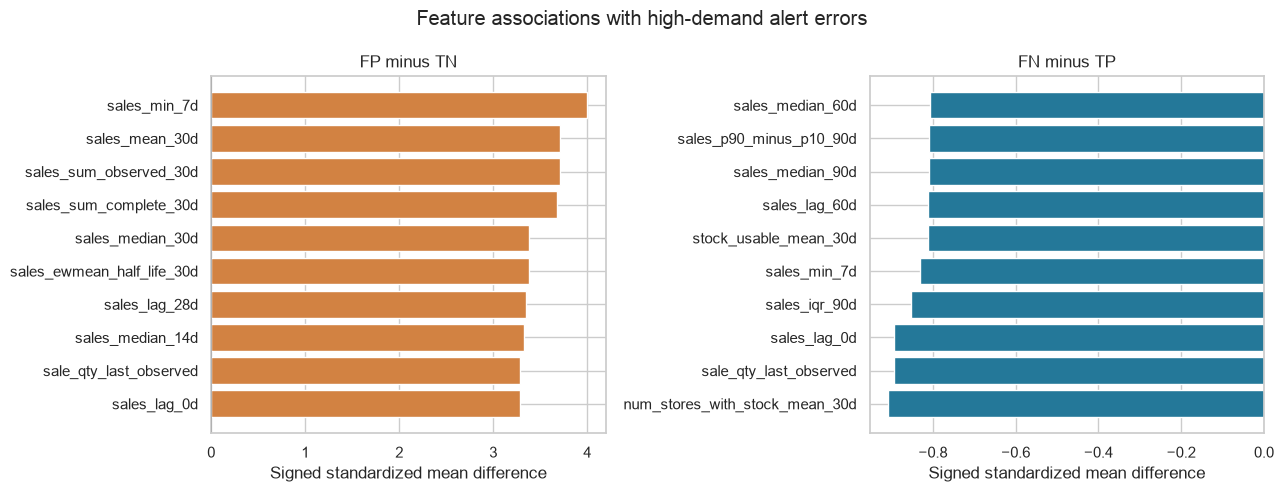

Largest historical-input shifts among fitted, non-calendar features:


,feature,family,n_a,n_b,smd,ks_d,missing_rate_difference,constant_shift
769,sales_skewness_30d,higher_order,1232,1232,0.893272,0.431818,0.0,False
666,sales_observed_days_30d,aggregated,1232,1232,0.569489,0.180195,0.0,False
671,sales_min_30d,aggregated,1232,1232,0.479169,0.628247,0.0,False
761,discount_deviation_from_mean_30d_pp,deviation,1232,1232,-0.430387,0.211851,0.0,False
770,sales_excess_kurtosis_30d,higher_order,1232,1232,-0.391579,0.318994,0.0,False
800,peer_complete_30d_count,competition,1232,1232,0.350385,0.182630,0.0,False
654,sales_observed_days_14d,aggregated,1232,1232,-0.262286,0.033279,0.0,False
760,price_deviation_from_median_30d_fraction,deviation,1232,1232,-0.246252,0.224026,0.0,False
792,peer_reporting_fraction_today,competition,1232,1232,-0.241727,0.028409,0.0,False
798,peer_discount_mean,competition,1232,1232,-0.229190,0.127435,0.0,False


In [37]:
primary_profiles = profile_stats[profile_stats.role.eq("final_test") & profile_stats.model.eq(REFERENCE_MODEL)
                                & profile_stats.event.eq("high_demand_q75") & profile_stats.used_by_model
                                & profile_stats.enough_observations].copy()
for comparison, part in primary_profiles.groupby("comparison"):
    print(comparison, "(positive SMD means higher feature values in the error group)")
    display(part.assign(abs_smd=part.smd.abs()).nlargest(12, "abs_smd")[[
        "feature", "family", "n_a", "n_b", "mean_a", "mean_b", "smd", "ks_d", "missing_rate_difference"
    ]])
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, comparison in zip(axes, ["FP_minus_TN", "FN_minus_TP"]):
    part = primary_profiles[primary_profiles.comparison.eq(comparison)].dropna(subset=["smd"])
    part = part.assign(abs_smd=part.smd.abs()).nlargest(10, "abs_smd").sort_values("smd")
    ax.barh(part.feature, part.smd, color=np.where(part.smd.ge(0), "#d28242", "#247899"))
    ax.axvline(0, color="black", linewidth=.7)
    ax.set(title=comparison.replace("_", " "), xlabel="Signed standardized mean difference")
fig.suptitle("Feature associations with high-demand alert errors")
fig.tight_layout(); fig.savefig(ANALYSIS_DIR / "error_group_smd.png", dpi=160)
plt.show()

matched_drift = pd.read_csv(ANALYSIS_DIR / "matched_product_drift.csv")
used_final = json.loads((ANALYSIS_ROOT / "data/modeling/final_fit.json").read_text())["used_feature_columns"]
print("Largest historical-input shifts among fitted, non-calendar features:")
drift = matched_drift[matched_drift.role.eq("final_test") & matched_drift.feature.isin(used_final)
                      & matched_drift.availability.eq("historical")].copy()
display(drift.assign(abs_smd=drift.smd.abs()).nlargest(12, "abs_smd")[[
    "feature", "family", "n_a", "n_b", "smd", "ks_d", "missing_rate_difference", "constant_shift"
]])

### What the fitted functions learned: native SHAP

Native SHAP is calculated for the saved final CatBoost model and the saved weekly CatBoost / best static XGBoost models on the same last development cohort. Each decomposition must reconstruct the native model output. Final XGBoost predictions are not generated.

`native expected value + all feature SHAP values = raw model output`. Negative raw sales forecasts are then clipped to zero. That clipping adjustment is stored separately; SHAP must not be falsely presented as already explaining the clipped result. A log-model decomposition would remain in log1p-output units until inverse transformation.

Feature-level mean absolute SHAP and grouped-family contributions answer different questions. `mean_abs_family_sum` first adds the signed contributions within a family, then takes absolute values; `sum_mean_abs_features` retains cancellation between correlated members. Neither is a causal effect, a fraction of explained variance, or a significance test. Cross-product price or stock associations are not price elasticity or proof that stock creates demand.

Final CatBoost: largest mean absolute contributions:


,explained_model,role,feature,family,mean_abs_shap,mean_shap,feature_shap_spearman
355,weekly_catboost_raw_mae_no_metadata,final_test,sales_sum_complete_7d,aggregated,1960.917787,355.695523,0.894369
436,weekly_catboost_raw_mae_no_metadata,final_test,sales_ewmean_half_life_7d,aggregated,1845.363762,-446.861786,0.952206
366,weekly_catboost_raw_mae_no_metadata,final_test,sales_mean_14d,aggregated,1626.214049,-8.426893,0.102100
349,weekly_catboost_raw_mae_no_metadata,final_test,stock_usable_last_observed,main,1583.353270,259.710261,0.970085
360,weekly_catboost_raw_mae_no_metadata,final_test,sales_median_7d,aggregated,1435.659232,116.663141,0.910968
347,weekly_catboost_raw_mae_no_metadata,final_test,sale_qty_last_observed,main,1368.026186,-173.668808,0.784633
394,weekly_catboost_raw_mae_no_metadata,final_test,sales_sum_observed_90d,aggregated,1352.210035,64.995866,0.433805
370,weekly_catboost_raw_mae_no_metadata,final_test,sales_median_14d,aggregated,1282.472788,-84.170050,0.088639
437,weekly_catboost_raw_mae_no_metadata,final_test,sales_ewmean_half_life_30d,aggregated,1130.092215,-146.415359,0.914799
390,weekly_catboost_raw_mae_no_metadata,final_test,sales_median_60d,aggregated,1028.544768,-117.319994,-0.316337


Grouped-family contributions:


,explained_model,role,family,features,mean_abs_family_sum,sum_mean_abs_features
20,weekly_catboost_raw_mae_no_metadata,final_test,aggregated,62,20572.680105,25153.621242
18,weekly_catboost_raw_mae_no_metadata,final_test,main,12,3142.566098,4058.996425
21,weekly_catboost_raw_mae_no_metadata,final_test,temporal,23,1363.915622,1681.978308
23,weekly_catboost_raw_mae_no_metadata,final_test,velocity_acceleration,6,696.724488,820.123691
24,weekly_catboost_raw_mae_no_metadata,final_test,higher_order,16,648.059194,1040.663487
22,weekly_catboost_raw_mae_no_metadata,final_test,deviation,5,630.677174,972.366417
19,weekly_catboost_raw_mae_no_metadata,final_test,domain,6,286.242794,511.053212
25,weekly_catboost_raw_mae_no_metadata,final_test,competition,14,276.197312,385.931527
26,weekly_catboost_raw_mae_no_metadata,final_test,cyclical,26,247.723758,542.818016


Native-output additivity checks:


products  \
role          explained_model                                  
development_3 rotating_xgboost_raw_mae_no_metadata      1191   
              weekly_catboost_raw_mae_no_metadata       1191   
final_test    weekly_catboost_raw_mae_no_metadata       1232   

                                                    max_absolute_additivity_error  \
role          explained_model                                                       
development_3 rotating_xgboost_raw_mae_no_metadata                   3.867937e-01   
              weekly_catboost_raw_mae_no_metadata                    8.149073e-10   
final_test    weekly_catboost_raw_mae_no_metadata                    4.656613e-10   

                                                    clipped_forecasts  
role          explained_model                                          
development_3 rotating_xgboost_raw_mae_no_metadata                 10  
              weekly_catboost_raw_mae_no_metadata                   7  
final_test    weekly_catboost_raw_mae_no_metadata                  23

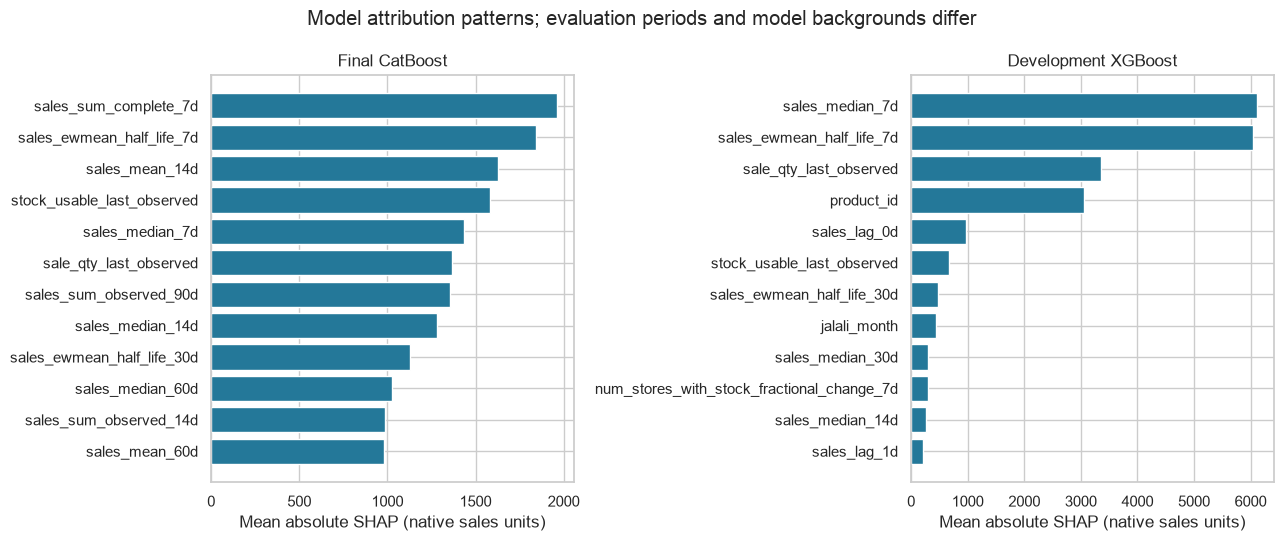

Local explanations for the largest final error regressions:
Product P_0402


,product_id,actual,baseline,forecast,native_expected_value,native_output,postprocessing_adjustment
2783,P_0402,1215762.65,1335734.3,891316.557408,22883.219695,891316.557408,0.0


,feature,family,feature_value,contribution
144,product_id,main,P_0402,167053.729393
145,Level1,main,L1_001,36450.576267
146,stock_usable_last_observed,main,489978.43,36179.945539
147,sales_ewmean_half_life_30d,aggregated,40902.02527163378,33763.219680
148,sales_mean_30d,aggregated,44524.47666666666,31835.539526
149,sales_sum_observed_180d,aggregated,6025315.529999999,30950.148018
150,sales_sum_observed_30d,aggregated,1335734.2999999998,27087.350621
151,num_stores_with_stock_fractional_change_7d,velocity_acceleration,-0.043596730245231585,-26970.972371
152,OTHER_FEATURES,other,NaN,532083.801042


Product P_0119


,product_id,actual,baseline,forecast,native_expected_value,native_output,postprocessing_adjustment
2500,P_0119,354991.41,443083.81,613904.006795,22883.219695,613904.006795,0.0


,feature,family,feature_value,contribution
162,sales_median_30d,aggregated,13846.765,36813.097485
163,sales_sum_observed_180d,aggregated,2421785.1499999994,34359.873489
164,sales_mean_30d,aggregated,14769.460333333334,32176.551694
165,sales_ewmean_half_life_30d,aggregated,15740.00182619158,30906.558777
166,sales_median_7d,aggregated,18584.8,27883.629097
167,sales_sum_observed_30d,aggregated,443083.81000000006,27162.719857
168,sales_mean_14d,aggregated,15525.35,26254.213151
169,sales_sum_observed_14d,aggregated,217354.9,24900.661572
170,OTHER_FEATURES,other,NaN,350563.481978


In [38]:
shap_global = pd.read_csv(ANALYSIS_DIR / "shap_global.csv")
shap_families = pd.read_csv(ANALYSIS_DIR / "shap_families.csv")
shap_rows = pd.read_parquet(ANALYSIS_DIR / "shap_reconstruction.parquet")
shap_local = pd.read_csv(ANALYSIS_DIR / "shap_local_cases.csv")
print("Final CatBoost: largest mean absolute contributions:")
display(shap_global[shap_global.role.eq("final_test")].nlargest(20, "mean_abs_shap"))
print("Grouped-family contributions:")
display(shap_families[shap_families.role.eq("final_test")].sort_values("mean_abs_family_sum", ascending=False))
print("Native-output additivity checks:")
display(shap_rows.groupby(["role", "explained_model"]).agg(
    products=("product_id", "size"), max_absolute_additivity_error=("shap_reconstruction_error", lambda s: s.abs().max()),
    clipped_forecasts=("postprocessing_adjustment", lambda s: s.gt(0).sum())
))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, role, model_name, title in [
    (axes[0], "final_test", REFERENCE_MODEL, "Final CatBoost"),
    (axes[1], "development_3", analysis_results["development_xgboost_reference"], "Development XGBoost"),
]:
    part = shap_global[shap_global.role.eq(role) & shap_global.explained_model.eq(model_name)].nlargest(12, "mean_abs_shap").sort_values("mean_abs_shap")
    ax.barh(part.feature, part.mean_abs_shap, color="#247899")
    ax.set(title=title, xlabel="Mean absolute SHAP (native sales units)")
fig.suptitle("Model attribution patterns; evaluation periods and model backgrounds differ")
fig.tight_layout(); fig.savefig(ANALYSIS_DIR / "native_shap_importance.png", dpi=160)
plt.show()

print("Local explanations for the largest final error regressions:")
case_ids = final_errors.nlargest(2, "extra_squared_error").product_id.tolist()
for product in case_ids:
    print("Product", product)
    display(shap_rows[shap_rows.role.eq("final_test") & shap_rows.product_id.eq(product)][[
        "product_id", "actual", "baseline", "forecast", "native_expected_value", "native_output", "postprocessing_adjustment"
    ]])
    display(shap_local[shap_local.role.eq("final_test") & shap_local.product_id.eq(product)][[
        "feature", "family", "feature_value", "contribution"
    ]])

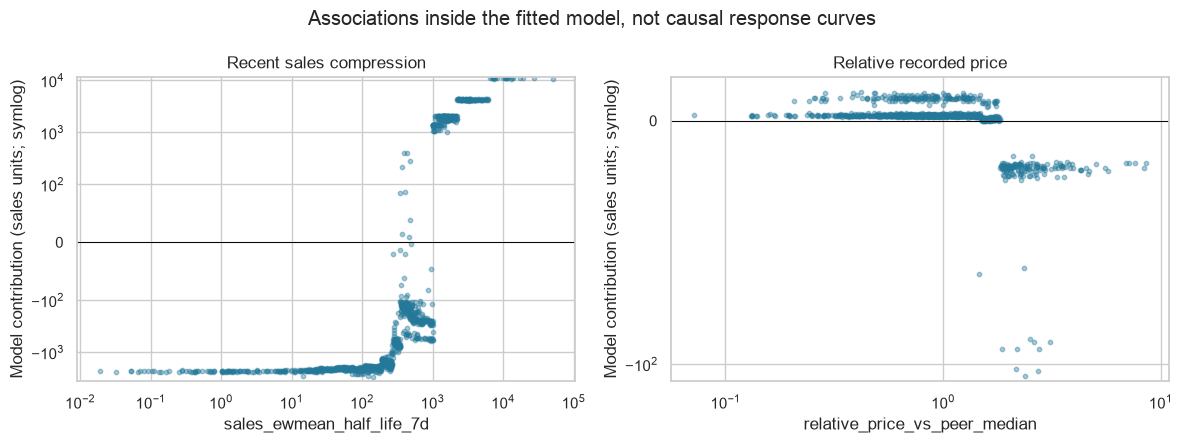

In [39]:
shap_values = pd.read_parquet(ANALYSIS_DIR / "shap_values_final_test_catboost.parquet")
input_features = pd.read_parquet(ANALYSIS_ROOT / "data/processed/features.parquet")
shap_dependence = shap_values.merge(input_features, on=["forecast_origin", "product_id"], validate="one_to_one")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, feature, title in [
    (axes[0], "sales_ewmean_half_life_7d", "Recent sales compression"),
    (axes[1], "relative_price_vs_peer_median", "Relative recorded price"),
]:
    valid = shap_dependence[feature].notna() & shap_dependence[feature].gt(0)
    ax.scatter(shap_dependence.loc[valid, feature], shap_dependence.loc[valid, "shap__" + feature], s=10, alpha=.4, color="#247899")
    ax.set_xscale("log"); ax.set_yscale("symlog", linthresh=100)
    ax.axhline(0, color="black", linewidth=.7)
    ax.set(title=title, xlabel=feature, ylabel="Model contribution (sales units; symlog)")
fig.suptitle("Associations inside the fitted model, not causal response curves")
fig.tight_layout(); fig.savefig(ANALYSIS_DIR / "shap_dependence.png", dpi=160)
plt.show()

### Interpretation of the actual diagnostics

The following interpretation is generated from the saved analysis tables. It distinguishes point estimates, uncertainty, alert behavior, error concentration and the fitted function's associations.

In [40]:
main = final_stats.loc[REFERENCE_MODEL]
comparison = paired_stats[paired_stats.role.eq("final_test") & paired_stats.model.eq(REFERENCE_MODEL)].iloc[0]
model_alerts = alert_stats[alert_stats.role.eq("final_test") & alert_stats.model.eq(REFERENCE_MODEL)].set_index("event")
high = model_alerts.loc["high_demand_q75"]
growth = model_alerts.loc["growth_25pct"]
decline = model_alerts.loc["decline_25pct"]
family = shap_families[shap_families.role.eq("final_test")]
history_share = 100 * family.loc[family.family.eq("aggregated"), "sum_mean_abs_features"].sum() / family.sum_mean_abs_features.sum()
insights = f"""
**The model mostly captures historical sales level and product scale.** Aggregated history accounts for
about **{history_share:.1f}%** of the sum of mean absolute feature attributions on the final cohort.
Recent complete sales, decayed sales means, medians, and last usable stock/sales measurements are prominent.
The high-demand alert has **{100*high.precision:.1f}% precision** and **{100*high.recall:.1f}% recall**
at the historical threshold of **{high.threshold:,.2f}** units. Its ROC AUC is **{high.roc_auc:.3f}**,
but the historical-rate baseline already ranks product volume very well. This is not proof that the model
can anticipate unexpected changes or estimate causal price effects.

**Demand changes are harder.** For growth of at least 25%, recall is **{100*growth.recall:.1f}%**
with precision **{100*growth.precision:.1f}%**. Declines of at least 25% have recall
**{100*decline.recall:.1f}%**. Those numbers describe the fixed alert definitions; no threshold was tuned
against the final outcome. TN/FP/FN/TP are meaningful only relative to those definitions.

**Typical errors improved, while a small tail remains problematic.** The model is closer than the baseline
for **{100*comparison.product_win_fraction:.1f}%** of products. However, the largest 1% of SKU squared
errors account for **{100*main.top_1pct_squared_error_share:.1f}%** of total squared error.
This explains how MAE can improve while RMSE becomes worse. The detailed SKU/category tables identify
where that tail comes from.

**Small distribution shifts are not the same as small forecast errors.** Prediction-minus-actual marginal
SMD is **{main.predicted_actual_smd:.3f}** and empirical KS distance is **{main.ks_d:.3f}**,
while total bias is **{main.bias_pct:.2f}%** and WAPE remains **{main.wape_pct:.2f}%**.
Wide differences in product scale can make marginal standardized bias look small. Product-level paired
errors remain the primary accuracy evidence.

**The uncertainty analysis tempers the point estimate.** WAPE improvement is
**{comparison.paired_wape_gain_pp:.2f} percentage points**, with a 95% category-cluster bootstrap interval
of **[{comparison.wape_gain_ci_low:.2f}, {comparison.wape_gain_ci_high:.2f}]**.
The category sign-flip p-value is **{comparison.cluster_signflip_p:.3f}**. The interval spans zero,
so this procedure does not resolve a general improvement. Its assumptions and fixed-horizon nature also
prevent a broad claim about future temporal performance.

**The raw-scale model struggles near zero.** It produces **{int(main.zero_prediction_positive_actual)}**
zero forecasts for products with positive realized 30-day sales. Native explanations keep negative raw
outputs separate from the clipping that turns them into zero. That mechanism helps explain poor relative
accuracy for small/sparse products even when their aggregate absolute error improves.

**FP/FN feature differences are diagnostic associations.** High-demand false positives are few
(**{int(high.FP)}**), versus **{int(high.FN)}** false negatives. Their SMD/KS profiles have limited support
and are affected by conditioning on the threshold. Use the case identifiers and local explanations to
investigate these products; do not treat the profiles as causal drivers or a newly validated decision rule.

**Nothing was refitted or reselected.** These are retrospective diagnostics on the existing reports.
The original model, predictions, metrics and refinement decisions are unchanged. No new XGBoost final-test
score or fresh external test estimate has been produced.
"""
display(Markdown(insights))
assert analysis_results["upstream_artifacts_unchanged"]
print("Analysis artifacts:")
for artifact in sorted(ANALYSIS_DIR.iterdir()):
    if artifact.is_file(): print(" ", artifact.name)


**The model mostly captures historical sales level and product scale.** Aggregated history accounts for
about **71.5%** of the sum of mean absolute feature attributions on the final cohort.
Recent complete sales, decayed sales means, medians, and last usable stock/sales measurements are prominent.
The high-demand alert has **98.3% precision** and **90.5% recall**
at the historical threshold of **20,919.07** units. Its ROC AUC is **0.995**,
but the historical-rate baseline already ranks product volume very well. This is not proof that the model
can anticipate unexpected changes or estimate causal price effects.

**Demand changes are harder.** For growth of at least 25%, recall is **26.2%**
with precision **67.3%**. Declines of at least 25% have recall
**47.1%**. Those numbers describe the fixed alert definitions; no threshold was tuned
against the final outcome. TN/FP/FN/TP are meaningful only relative to those definitions.

**Typical errors improved, while a small tail remains problematic.** The model is closer than the baseline
for **62.4%** of products. However, the largest 1% of SKU squared
errors account for **80.4%** of total squared error.
This explains how MAE can improve while RMSE becomes worse. The detailed SKU/category tables identify
where that tail comes from.

**Small distribution shifts are not the same as small forecast errors.** Prediction-minus-actual marginal
SMD is **-0.027** and empirical KS distance is **0.029**,
while total bias is **-6.24%** and WAPE remains **17.73%**.
Wide differences in product scale can make marginal standardized bias look small. Product-level paired
errors remain the primary accuracy evidence.

**The uncertainty analysis tempers the point estimate.** WAPE improvement is
**1.48 percentage points**, with a 95% category-cluster bootstrap interval
of **[-0.77, 3.74]**.
The category sign-flip p-value is **0.207**. The interval spans zero,
so this procedure does not resolve a general improvement. Its assumptions and fixed-horizon nature also
prevent a broad claim about future temporal performance.

**The raw-scale model struggles near zero.** It produces **23**
zero forecasts for products with positive realized 30-day sales. Native explanations keep negative raw
outputs separate from the clipping that turns them into zero. That mechanism helps explain poor relative
accuracy for small/sparse products even when their aggregate absolute error improves.

**FP/FN feature differences are diagnostic associations.** High-demand false positives are few
(**5**), versus **31** false negatives. Their SMD/KS profiles have limited support
and are affected by conditioning on the threshold. Use the case identifiers and local explanations to
investigate these products; do not treat the profiles as causal drivers or a newly validated decision rule.

**Nothing was refitted or reselected.** These are retrospective diagnostics on the existing reports.
The original model, predictions, metrics and refinement decisions are unchanged. No new XGBoost final-test
score or fresh external test estimate has been produced.


Analysis artifacts:
  alert_cases.parquet
  alert_confusion_matrices.png
  alert_statistics.csv
  category_errors.csv
  distribution_and_errors.png
  error_feature_profiles.csv
  error_group_smd.png
  forecast_reliability.csv
  historical_alert_thresholds.csv
  matched_product_drift.csv
  native_shap_importance.png
  paired_cluster_inference.csv
  paired_cluster_intervals.png
  prediction_errors.parquet
  protocol.json
  regression_statistics.csv
  results.json
  shap_dependence.png
  shap_families.csv
  shap_global.csv
  shap_local_cases.csv
  shap_reconstruction.parquet
  shap_values_development_3_catboost.parquet
  shap_values_development_3_xgboost.parquet
  shap_values_final_test_catboost.parquet
